# YOLOv5su przed i po fine-tuningu na BDD100K

Wagi startowe z COCO porównujemy z `best.pt` z 30-epokowego treningu na 15 000 zdjęć. Oba modele oglądają te same 500 zdjęć testowych przy rozdzielczości wejściowej 960 px. Wyniki i obrazy są zapisane w notebooku.

Do ponownego uruchomienia potrzebny jest lokalny zestaw danych przygotowany przez [notebook treningowy](lab2B_yolo_finetuning.ipynb), pliki wag `yolov5su.pt` i `best.pt` oraz środowisko z Ultralytics, PyTorch i Matplotlib.

In [1]:
import csv
import io
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, Markdown, display
from matplotlib.patches import Rectangle
from PIL import Image as PILImage

CACHE = Path("cache/yolo_finetuning")
DATASET = CACHE / "bdd_15000_seed42"
RUN = CACHE / "yolov5su_15000_960_30ep_seed42"
os.environ.setdefault("YOLO_CONFIG_DIR", str((CACHE / "ultralytics").resolve()))
if os.name == "nt":
    os.environ.setdefault("MIOPEN_FIND_MODE", "FAST")
    os.environ.setdefault("MIOPEN_CUSTOM_CACHE_DIR", str((CACHE / "miopen_kernels").resolve()))
    os.environ.setdefault("MIOPEN_USER_DB_PATH", str((CACHE / "miopen_db").resolve()))

os.environ["YOLO_OFFLINE"] = "true"

from ultralytics import YOLO

IMG_SIZE = 960
CONF = 0.25
DEVICE = 0 if torch.cuda.is_available() else "cpu"
BEFORE = "Przed (COCO)"
AFTER = "Po (BDD100K)"
LIGHT_PALETTE = {"Czerwone": "#ff4949", "Żółte": "#ffe031", "Zielone": "#69f355", "Nieokreślone": "#eeeeee"}
LIGHT_CLASSES = dict(zip(("red", "yellow", "green", "unknown"), LIGHT_PALETTE))
VARIANTS = {BEFORE: Path("yolov5su.pt"), AFTER: RUN / "weights/best.pt"}
TARGETS = {
    BEFORE: {"stop sign": "Znaki", "traffic light": "Sygnalizatory"},
    AFTER: {
        "traffic_sign": "Znaki",
        "traffic_light_red": "Sygnalizatory",
        "traffic_light_yellow": "Sygnalizatory",
        "traffic_light_green": "Sygnalizatory",
        "traffic_light_unknown": "Sygnalizatory",
    },
}

manifest = DATASET / "test.txt"
for artifact in (manifest, RUN / "test_ap.csv", RUN / "results.csv", *VARIANTS.values()):
    if not artifact.is_file():
        raise FileNotFoundError(artifact)

# Manifest ustala dokładnie ten sam zestaw zdjęć co notebook treningowy.
test_names = [Path(line).name for line in manifest.read_text(encoding="utf-8").splitlines() if line.strip()]
test_paths = [DATASET / "images/test" / name for name in test_names]
assert len(test_paths) == len(set(test_paths)) == 500
print(f"Zbiór testowy: {len(test_paths)} zdjęć. Urządzenie: {'GPU' if DEVICE == 0 else 'CPU'}.")

Zbiór testowy: 500 zdjęć. Urządzenie: GPU.


## Wspólna ocena lokalizacji

Dopasowujemy ramki w kolejności malejącej pewności, po jednej predykcji na obiekt, przy IoU ≥ 0,50. Oba modele mają próg confidence 0,25 oraz te same ustawienia inferencji. Przy sygnalizatorach oceniamy samo położenie ramki, niezależnie od koloru. Wagi COCO mają klasę `stop sign`, więc w wierszu „Znaki” mierzymy, ile wszystkich znaków BDD100K pokrywa ta pojedyncza klasa. Różnica dla znaków odzwierciedla również rozszerzenie zakresu klas.

In [2]:
def read_truth(path):
    with PILImage.open(path) as image:
        width, height = image.size
    labels = DATASET / "labels/test" / path.with_suffix(".txt").name
    groups = {"Znaki": [], "Sygnalizatory": []}
    light_colors = []
    for line in labels.read_text(encoding="utf-8").splitlines():
        class_id, cx, cy, w, h = map(float, line.split())
        group = "Znaki" if class_id == 0 else "Sygnalizatory"
        if class_id != 0:
            light_colors.append(list(LIGHT_PALETTE)[int(class_id) - 1])
        groups[group].append([
            (cx - w / 2) * width, (cy - h / 2) * height,
            (cx + w / 2) * width, (cy + h / 2) * height,
        ])
    return groups, light_colors


def predict(variant, weights):
    model = YOLO(str(weights))
    # Manifest wejściowy zachowuje ładowanie wsadowe i rozmiar obrazów.
    results = model.predict(
        str(manifest), stream=True, imgsz=IMG_SIZE, batch=4, conf=CONF,
        device=DEVICE, verbose=False,
    )
    predictions, light_colors = {}, {}
    for result in results:
        groups = {"Znaki": [], "Sygnalizatory": []}
        name = Path(result.path).name
        light_colors[name] = []
        for row in result.boxes.data.cpu().tolist():
            x1, y1, x2, y2, score, class_id = row
            label = result.names[int(class_id)]
            group = TARGETS[variant].get(label)
            if group:
                groups[group].append((score, [x1, y1, x2, y2]))
                if group == "Sygnalizatory":
                    light_colors[name].append(LIGHT_CLASSES.get(label.removeprefix("traffic_light_"), "COCO"))
        predictions[name] = groups
    if set(predictions) != set(test_names):
        raise RuntimeError("Lista predykcji różni się od listy zdjęć testowych.")
    return predictions, light_colors


truth, truth_colors = {}, {}
for path in test_paths:
    truth[path.name], truth_colors[path.name] = read_truth(path)

predictions, prediction_colors = {}, {}
for variant, weights in VARIANTS.items():
    predictions[variant], prediction_colors[variant] = predict(variant, weights)

In [3]:
def iou(box, candidates):
    intersection_size = np.maximum(
        np.minimum(box[2:], candidates[:, 2:]) -
        np.maximum(box[:2], candidates[:, :2]), 0
    )
    intersection = intersection_size.prod(axis=1)
    box_area = np.prod(box[2:] - box[:2])
    candidate_area = np.prod(candidates[:, 2:] - candidates[:, :2], axis=1)
    return intersection / np.maximum(box_area + candidate_area - intersection, 1e-9)


def match_boxes(expected, predicted):
    boxes = np.array(expected).reshape(-1, 4)
    remaining = np.arange(len(boxes))
    order = sorted(range(len(predicted)), key=lambda index: predicted[index][0], reverse=True)
    for pred_index in order:
        if len(remaining) == 0:
            break
        overlap = iou(np.array(predicted[pred_index][1]), boxes[remaining])
        best = overlap.argmax()
        if overlap[best] >= 0.5:
            yield remaining[best], pred_index
            remaining = np.delete(remaining, best)


def match_count(expected, predicted):
    return sum(1 for _ in match_boxes(expected, predicted))


def detection_metrics(variant, group):
    tp = fp = fn = 0
    for name in test_names:
        expected = truth[name][group]
        predicted = predictions[variant][name][group]
        matches = match_count(expected, predicted)
        tp += matches
        fp += len(predicted) - matches
        fn += len(expected) - matches
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * tp / max(2 * tp + fp + fn, 1)
    return tp, fp, fn, precision, recall, f1


def show_table(headers, rows):
    rows = [headers, ["---"] * len(headers), *rows]
    display(Markdown("\n".join("| " + " | ".join(map(str, row)) + " |" for row in rows)))


groups = ["Znaki", "Sygnalizatory"]
scores = {}
rows = []
for group in groups:
    for variant in VARIANTS:
        tp, fp, fn, precision, recall, f1 = detection_metrics(variant, group)
        scores[group, variant] = f1
        rows.append((group, variant, tp, fp, fn, f"{precision:.1%}", f"{recall:.1%}", f"{f1:.1%}"))

show_table(["Obiekty", "Model", "TP", "FP", "FN", "Precision", "Recall", "F1"], rows)
for group in groups:
    delta = 100 * (scores[group, AFTER] - scores[group, BEFORE])
    print(f"{group}: zmiana F1 o {delta:+.1f} p.p.")

| Obiekty | Model | TP | FP | FN | Precision | Recall | F1 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Znaki | Przed (COCO) | 9 | 0 | 1668 | 100.0% | 0.5% | 1.1% |
| Znaki | Po (BDD100K) | 1083 | 441 | 594 | 71.1% | 64.6% | 67.7% |
| Sygnalizatory | Przed (COCO) | 235 | 162 | 1186 | 59.2% | 16.5% | 25.9% |
| Sygnalizatory | Po (BDD100K) | 862 | 331 | 559 | 72.3% | 60.7% | 66.0% |

Znaki: zmiana F1 o +66.6 p.p.
Sygnalizatory: zmiana F1 o +40.1 p.p.


## Wizualizacja wyników na zdjęciach testowych

Każdy wiersz pokazuje to samo zdjęcie w trzech wersjach: etykiety BDD100K, predykcje YOLO na COCO i predykcje po fine-tuningu. **Turkusowe ramki** oznaczają znaki. Kolor ramki sygnalizatora pokazuje klasę z etykiety lub predykcji: czerwony, żółty, zielony lub biały dla nieokreślonego. Pomarańczowe ramki COCO oznaczają wykryty sygnalizator bez informacji o kolorze. Nad predykcjami podano trafienia (TP), fałszywe alarmy (FP) i pominięcia (FN) dla obu grup łącznie. W przypadku sygnalizatorów ocena dotyczy położenia ramki.

W każdym zestawie wybieramy zdjęcia rozłożone równomiernie na liście posortowanej według nazw plików. Każde zdjęcie pokazujemy raz. Wyniki dla pełnego testu są w tabeli powyżej.

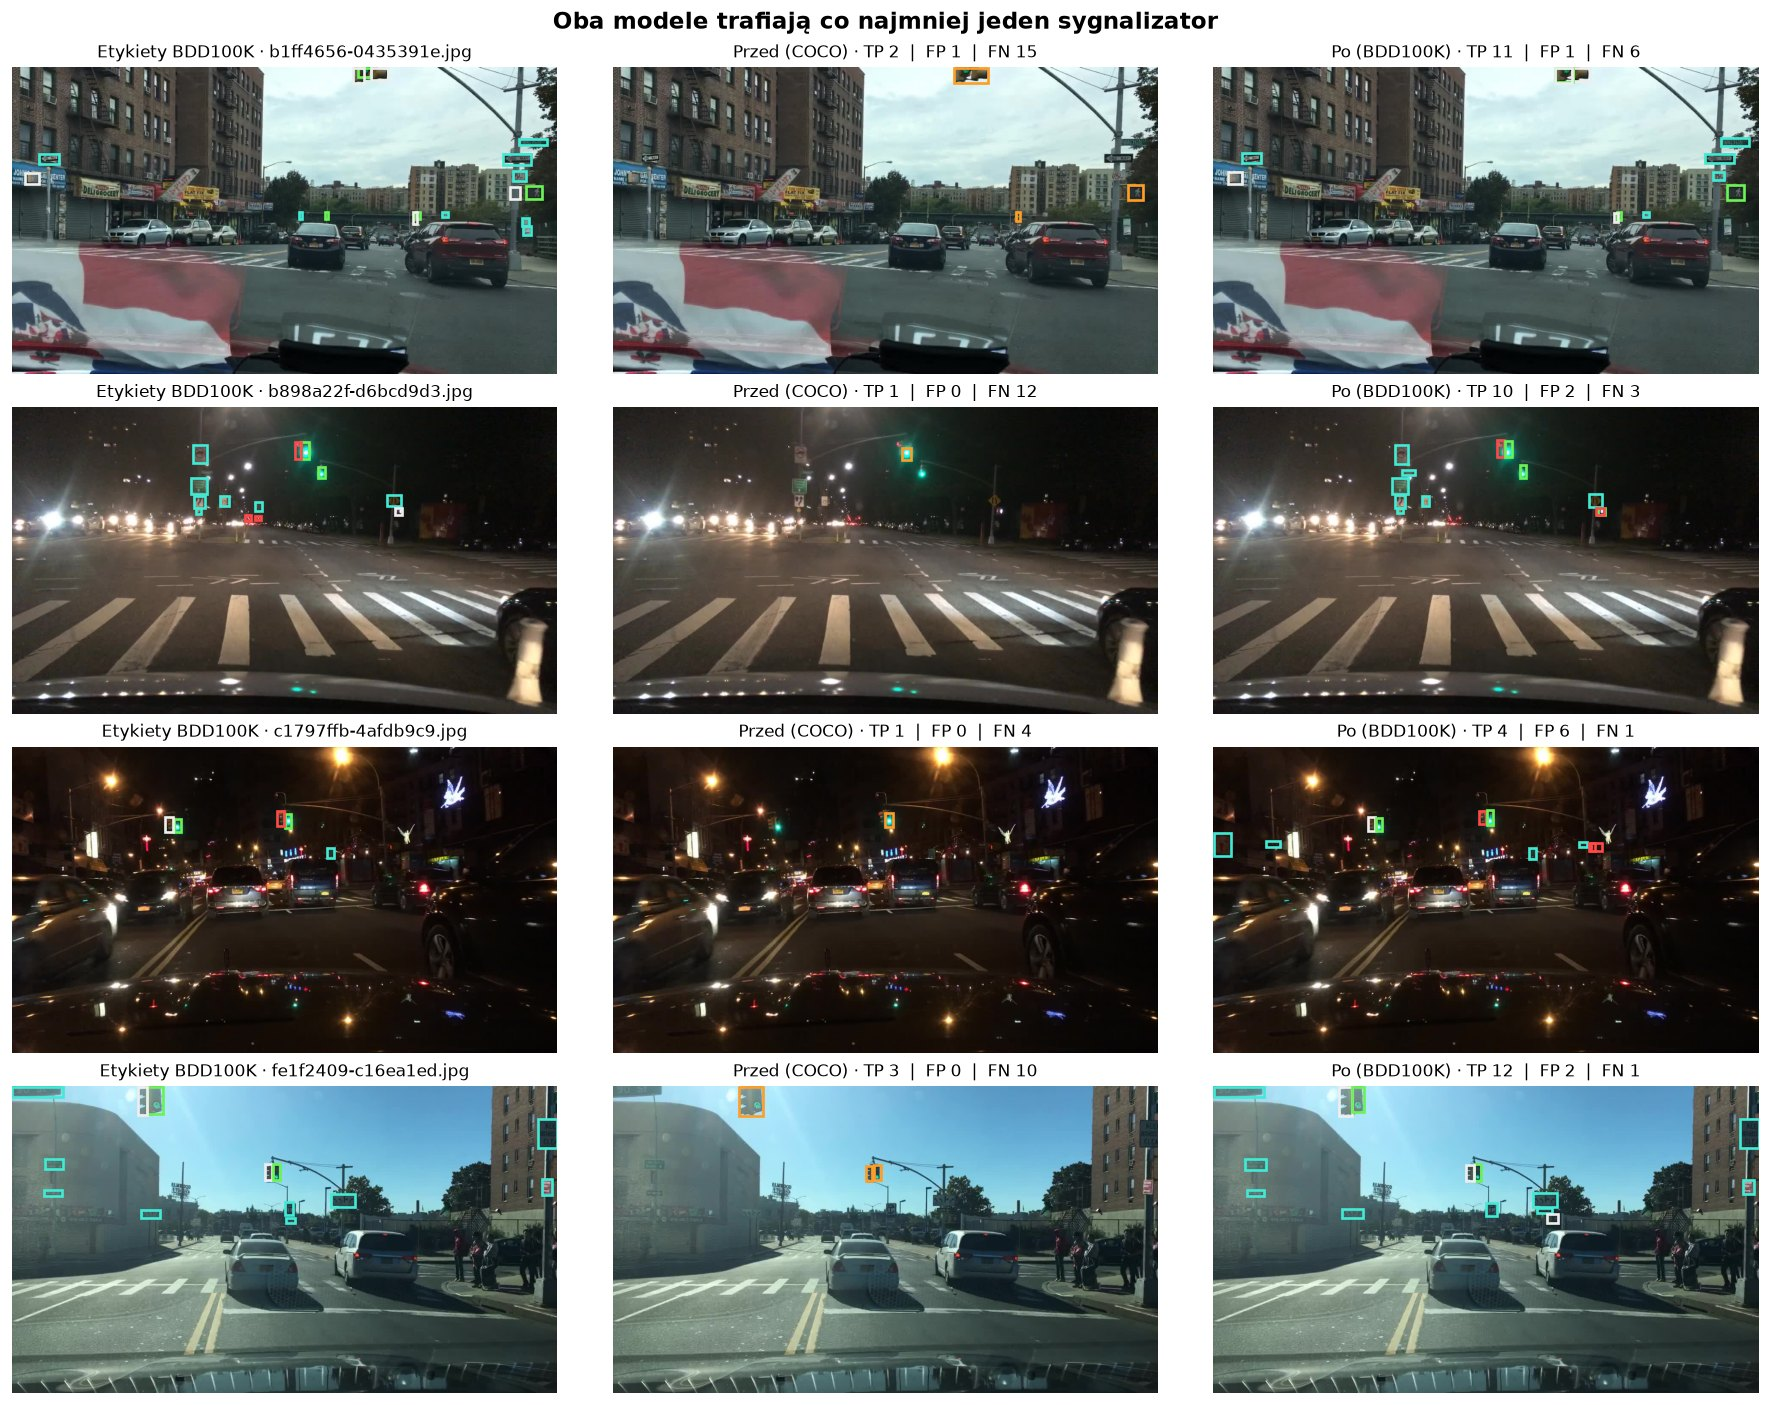

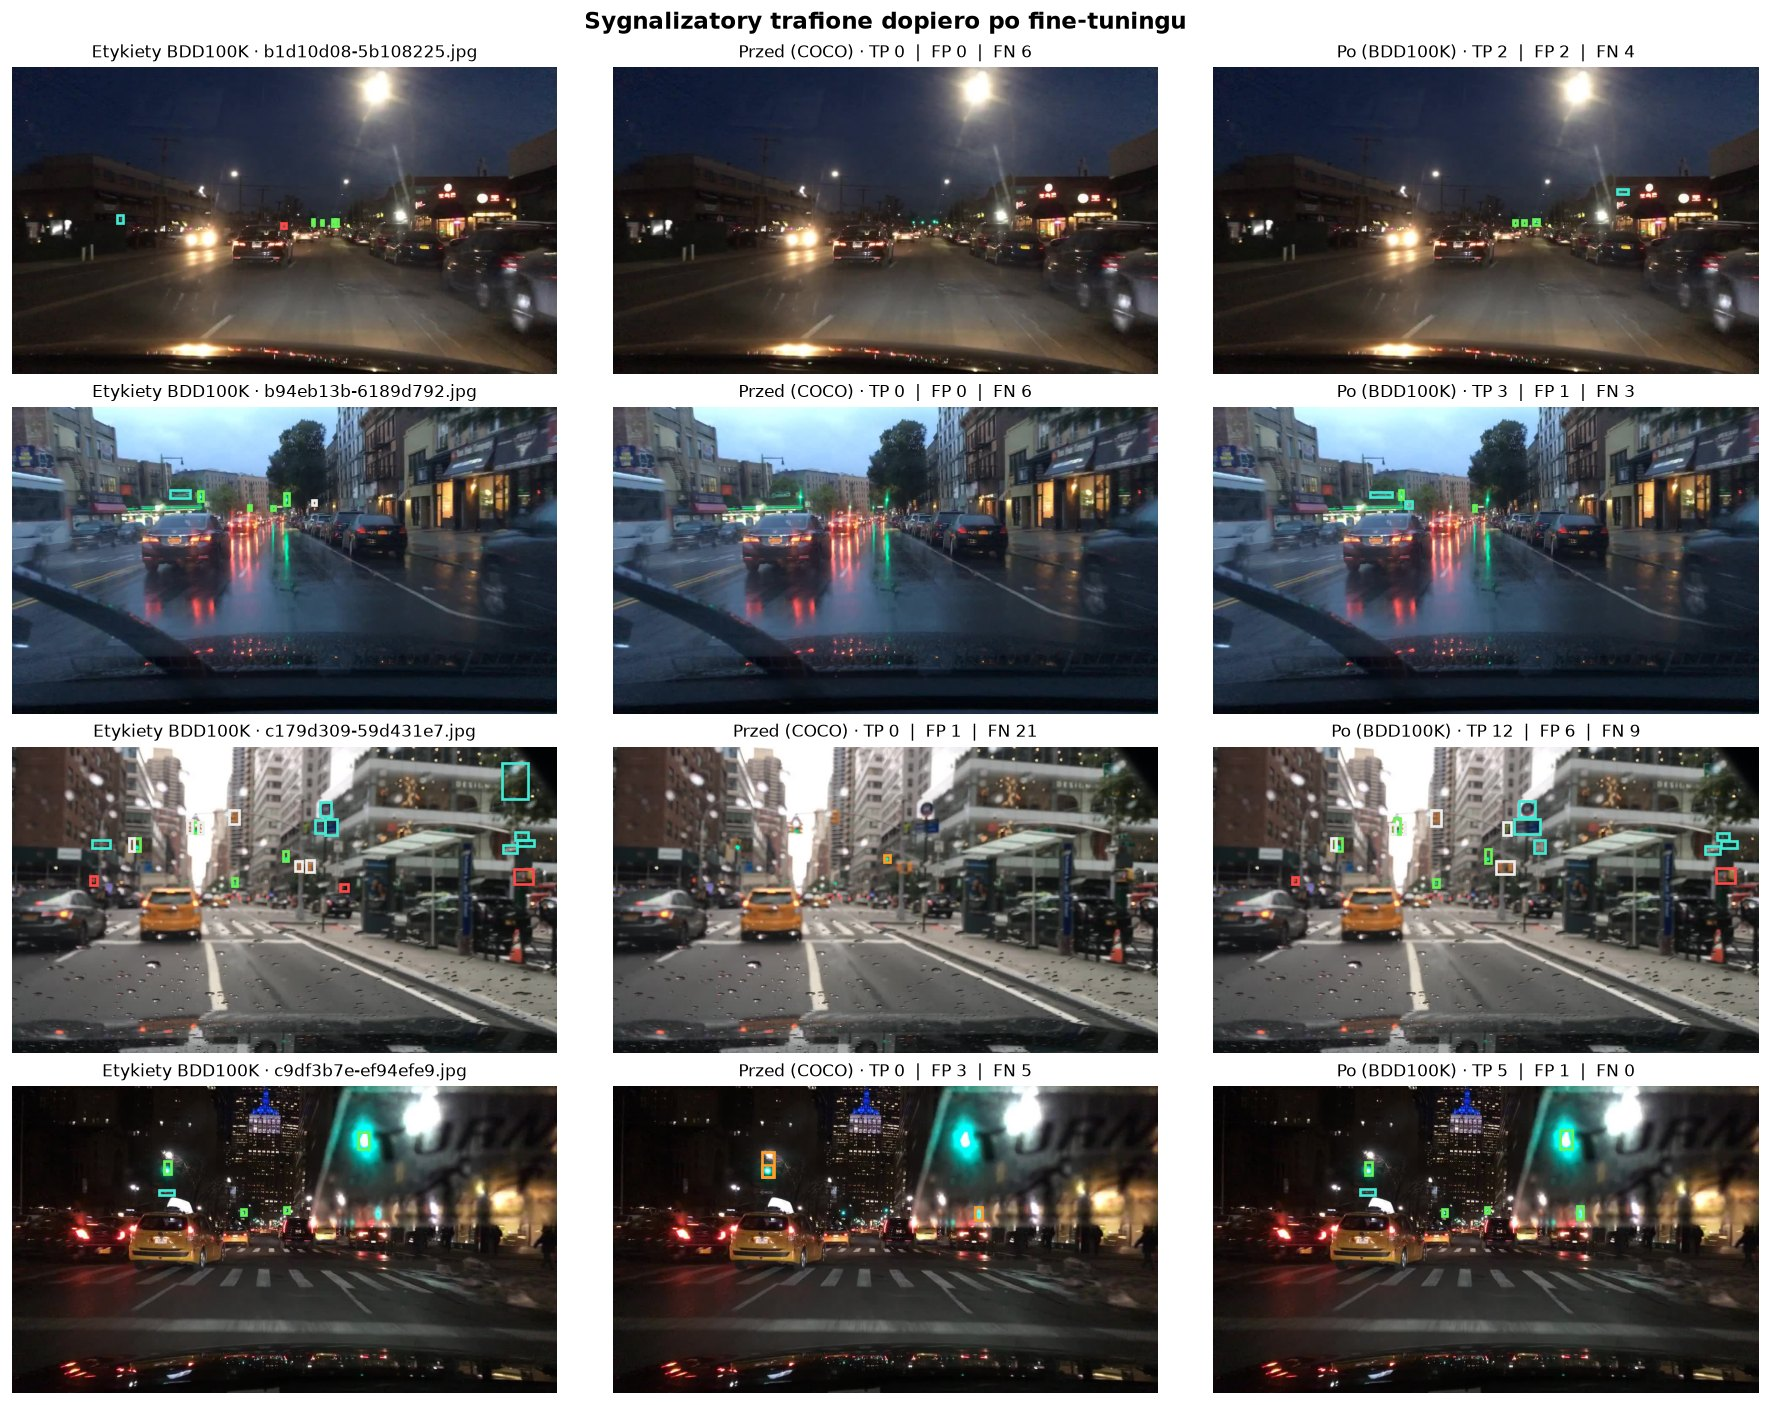

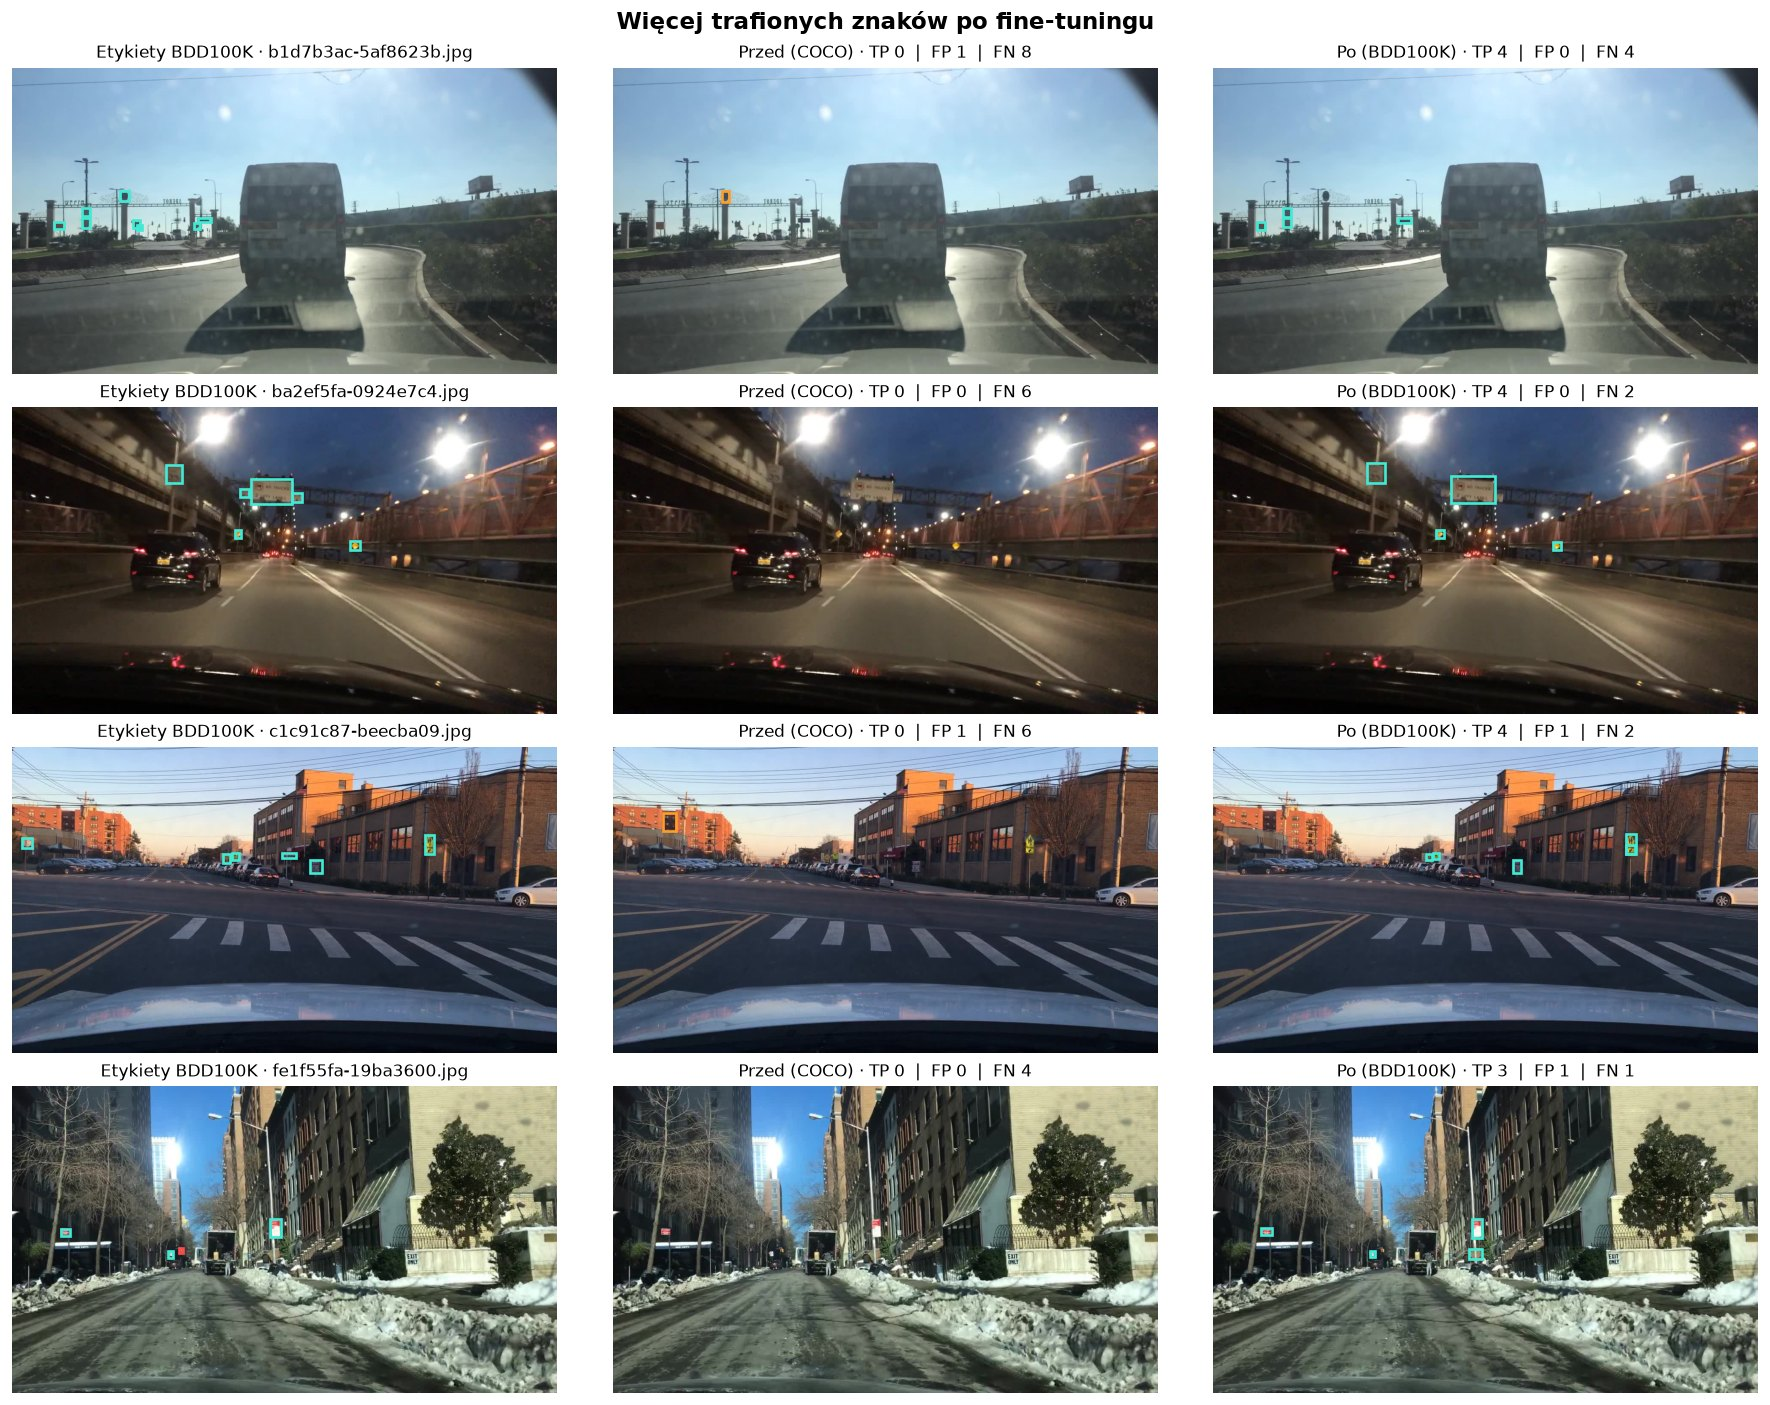

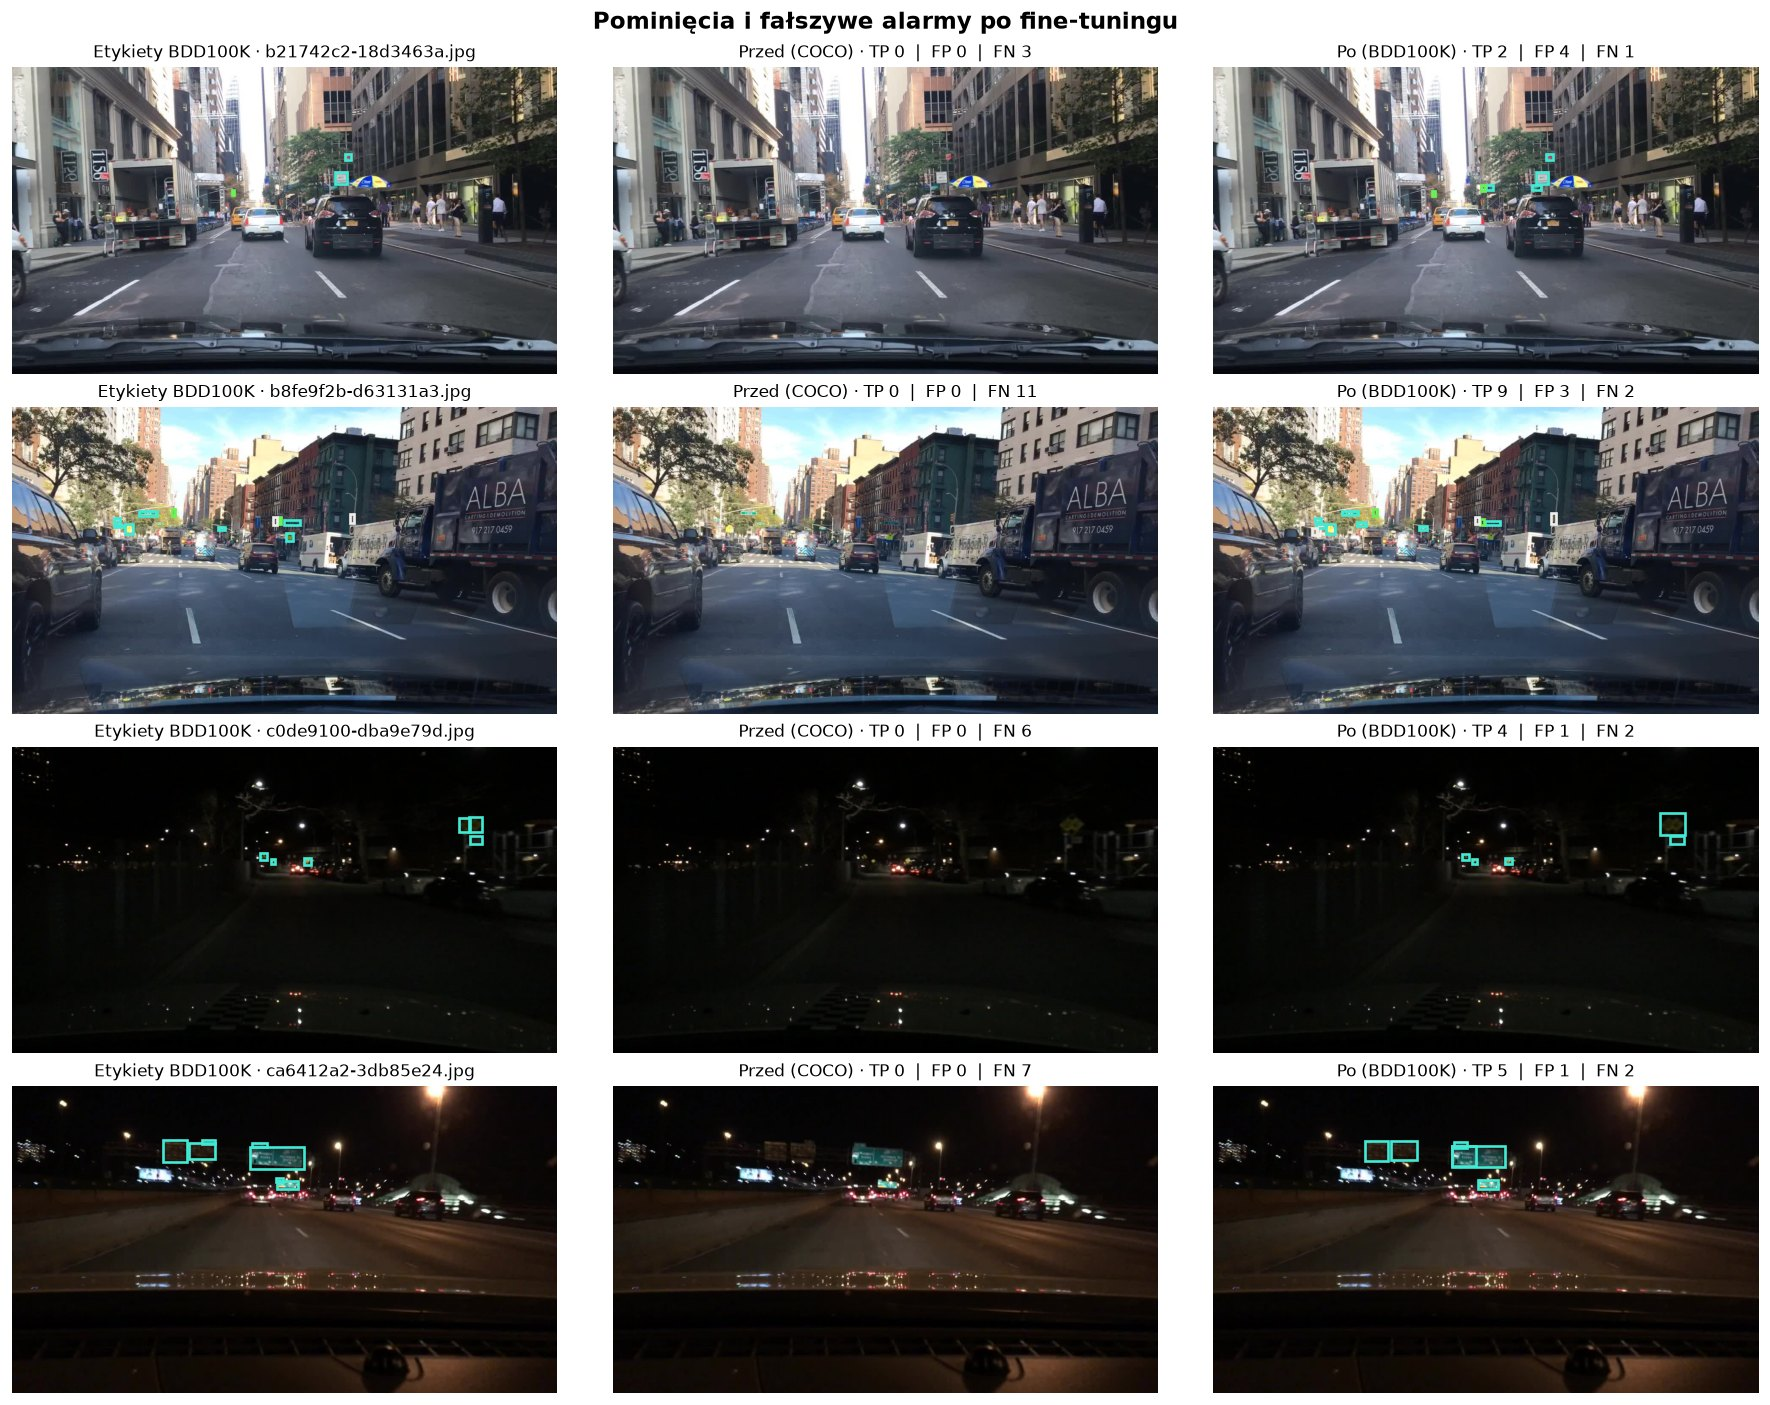

Zapisano porównania dla 16 różnych zdjęć testowych.


In [4]:
def show_figure(fig, format="png"):
    buffer = io.BytesIO()
    save_options = {"pil_kwargs": {"quality": 86}} if format == "jpeg" else {}
    fig.savefig(buffer, format=format, dpi=120, bbox_inches="tight", **save_options)
    plt.close(fig)
    display(Image(data=buffer.getvalue(), format=format))


colors = {"Znaki": "#41ead4", "COCO": "#ff9d27", **LIGHT_PALETTE}
per_image = {}
for name in sorted(test_names):
    per_image[name] = {}
    for variant in VARIANTS:
        per_image[name][variant] = {}
        for group in groups:
            expected = truth[name][group]
            predicted = predictions[variant][name][group]
            tp = match_count(expected, predicted)
            per_image[name][variant][group] = (tp, len(predicted) - tp, len(expected) - tp)


def plot_comparison(title, names):
    fig, axes = plt.subplots(
        len(names), 3, figsize=(15, 2.9 * len(names)), squeeze=False, layout="constrained",
    )
    fig.suptitle(title, fontsize=14, fontweight="bold")
    for name, row in zip(names, axes):
        with PILImage.open(DATASET / "images/test" / name) as image:
            pixels = np.array(image.convert("RGB"))
        panels = [("Etykiety BDD100K", truth[name], truth_colors[name], name)]
        for variant in VARIANTS:
            boxes = {
                group: [box for _, box in predictions[variant][name][group]]
                for group in groups
            }
            tp, fp, fn = map(sum, zip(*per_image[name][variant].values()))
            panels.append((variant, boxes, prediction_colors[variant][name], f"TP {tp}  |  FP {fp}  |  FN {fn}"))
        for ax, (label, boxes, light_colors, details) in zip(row, panels):
            ax.imshow(pixels)
            for group, rectangles in boxes.items():
                for index, (x1, y1, x2, y2) in enumerate(rectangles):
                    color = group if group == "Znaki" else light_colors[index]
                    ax.add_patch(Rectangle(
                        (x1, y1), x2 - x1, y2 - y1, fill=False,
                        edgecolor=colors[color], linewidth=1.6,
                    ))
            ax.set_title(f"{label} · {details}", fontsize=10)
            ax.set_axis_off()
    show_figure(fig, format="jpeg")


case_filters = [
    ("Oba modele trafiają co najmniej jeden sygnalizator",
     lambda before, after: before["Sygnalizatory"][0] > 0 and after["Sygnalizatory"][0] > 0),
    ("Sygnalizatory trafione dopiero po fine-tuningu",
     lambda before, after: before["Sygnalizatory"][0] == 0 and after["Sygnalizatory"][0] > 0),
    ("Więcej trafionych znaków po fine-tuningu",
     lambda before, after: after["Znaki"][0] > before["Znaki"][0]),
    ("Pominięcia i fałszywe alarmy po fine-tuningu",
     lambda before, after: any(fp > 0 for _, fp, _ in after.values())
     and any(fn > 0 for _, _, fn in after.values())),
]

shown = set()
for title, qualifies in case_filters:
    candidates = [
        name for name, result in per_image.items()
        if name not in shown and qualifies(result[BEFORE], result[AFTER])
    ]
    if candidates:
        indices = np.linspace(0, len(candidates) - 1, min(4, len(candidates)), dtype=int)
        names = [candidates[index] for index in indices]
        shown.update(names)
        plot_comparison(title, names)

print(f"Zapisano porównania dla {len(shown)} różnych zdjęć testowych.")

## Rozpoznawanie koloru po fine-tuningu

Model BDD100K przewiduje cztery klasy sygnalizatorów: czerwone, żółte, zielone i nieokreślone. COCO przewiduje wspólną klasę `traffic light`.

Przy confidence 0,25 i IoU ≥ 0,50 najpierw dopasowujemy ramki bez uwzględniania koloru. Przekątna tabeli pokazuje zgodne klasy, pola poza przekątną pokazują pomyłki koloru, a ostatnia kolumna pokazuje sygnalizatory bez dopasowanej ramki. Ostatni wiersz zlicza predykcje bez przypisanego obiektu.

In [5]:
color_names = list(LIGHT_PALETTE)
color_index = {name: index for index, name in enumerate(color_names)}
unmatched = len(color_names)
matrix = np.zeros((unmatched + 1, unmatched + 1), dtype=int)
for name in test_names:
    expected = truth[name]["Sygnalizatory"]
    predicted = predictions[AFTER][name]["Sygnalizatory"]
    actual_colors = truth_colors[name]
    model_colors = prediction_colors[AFTER][name]
    matched_gt, matched_pred = set(), set()
    for gt_index, pred_index in match_boxes(expected, predicted):
        matrix[color_index[actual_colors[gt_index]], color_index[model_colors[pred_index]]] += 1
        matched_gt.add(gt_index)
        matched_pred.add(pred_index)
    for index, color in enumerate(actual_colors):
        if index not in matched_gt:
            matrix[color_index[color], unmatched] += 1
    for index, color in enumerate(model_colors):
        if index not in matched_pred:
            matrix[unmatched, color_index[color]] += 1

localized = int(matrix[:unmatched, :unmatched].sum())
correct = int(np.trace(matrix))
total = int(matrix[:unmatched].sum())
assert (localized, int(matrix[unmatched].sum()), int(matrix[:, unmatched].sum())) == detection_metrics(AFTER, "Sygnalizatory")[:3]
show_table(
    ["Etykieta / predykcja", *color_names, "Pominięty"],
    [[label, *row] for label, row in zip([*color_names, "Fałszywy alarm"], matrix)],
)
yellow = color_index["Żółte"]
missed_yellow = int(matrix[yellow, unmatched])
total_yellow = int(matrix[yellow].sum())
display(Markdown(
    f"- **Kolor po trafieniu ramki:** {correct}/{localized} poprawnych klas "
    f"({correct / localized:.1%}, łącznie z klasą nieokreśloną).\n"
    f"- **Lokalizacja i klasa łącznie:** {correct}/{total} wszystkich oznaczonych "
    f"sygnalizatorów ({correct / total:.1%}).\n"
    f"- **Żółte światło:** {matrix[yellow, yellow]}/{total_yellow} z poprawną ramką "
    f"i klasą. Model pominął {missed_yellow}, a "
    f"{total_yellow - missed_yellow - matrix[yellow, yellow]} przypisał do innej klasy."
))

| Etykieta / predykcja | Czerwone | Żółte | Zielone | Nieokreślone | Pominięty |
| --- | --- | --- | --- | --- | --- |
| Czerwone | 191 | 2 | 3 | 7 | 146 |
| Żółte | 7 | 3 | 0 | 3 | 16 |
| Zielone | 0 | 0 | 390 | 8 | 198 |
| Nieokreślone | 16 | 0 | 13 | 219 | 199 |
| Fałszywy alarm | 102 | 2 | 142 | 85 | 0 |

- **Kolor po trafieniu ramki:** 803/862 poprawnych klas (93.2%, łącznie z klasą nieokreśloną).
- **Lokalizacja i klasa łącznie:** 803/1421 wszystkich oznaczonych sygnalizatorów (56.5%).
- **Żółte światło:** 3/29 z poprawną ramką i klasą. Model pominął 16, a 10 przypisał do innej klasy.

## AP na teście po fine-tuningu

Tu kolor sygnalizatora stanowi część klasy. AP mierzy działanie przy różnych progach pewności. AP50 wymaga IoU 0,50, a AP50–95 uśrednia wyniki dla progów IoU od 0,50 do 0,95. Wiersz mAP to średnia po pięciu klasach BDD100K.

| Klasa | AP50 | AP50–95 |
| --- | --- | --- |
| traffic_sign | 69.5% | 36.9% |
| traffic_light_red | 54.1% | 21.1% |
| traffic_light_yellow | 15.0% | 6.9% |
| traffic_light_green | 67.2% | 24.0% |
| traffic_light_unknown | 56.0% | 23.3% |
| mAP | 52.4% | 22.4% |

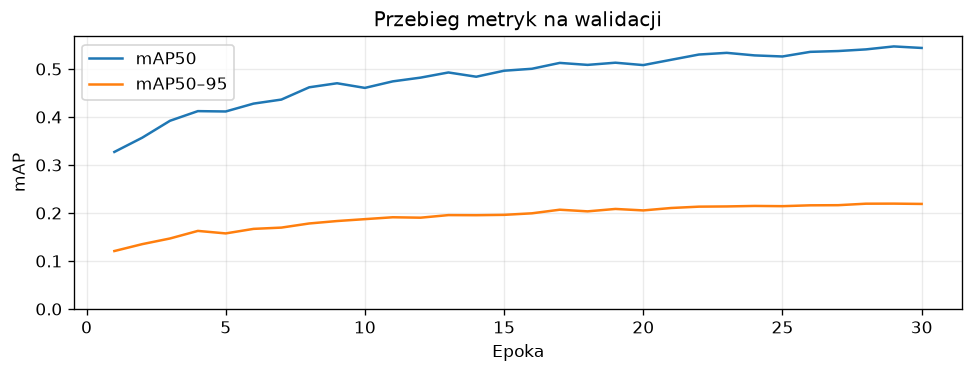

In [6]:
with (RUN / "test_ap.csv").open(encoding="utf-8", newline="") as file:
    test_ap = list(csv.DictReader(file))
ap_rows = [(r["Klasa"], f"{float(r['AP50']):.1%}", f"{float(r['AP50-95']):.1%}") for r in test_ap]
ap_rows.append((
    "mAP", f"{np.mean([float(r['AP50']) for r in test_ap]):.1%}",
    f"{np.mean([float(r['AP50-95']) for r in test_ap]):.1%}",
))
show_table(["Klasa", "AP50", "AP50–95"], ap_rows)

with (RUN / "results.csv").open(encoding="utf-8", newline="") as file:
    history = list(csv.DictReader(file))
epochs = [int(row["epoch"]) for row in history]
assert epochs == list(range(1, 31))
fig, ax = plt.subplots(figsize=(8, 3), layout="constrained")
for label, column in [("mAP50", "metrics/mAP50(B)"), ("mAP50–95", "metrics/mAP50-95(B)")]:
    ax.plot(epochs, [float(row[column]) for row in history], label=label)
ax.set(xlabel="Epoka", ylabel="mAP", title="Przebieg metryk na walidacji")
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(alpha=0.25)
show_figure(fig)

## Wykresy Ultralytics po fine-tuningu

Wykresy poniżej pochodzą z tego samego przebiegu treningu i oceny `best.pt`. Pierwszy wykres przedstawia historię epok. Krzywe detekcji i macierze pomyłek pochodzą z podfolderu `test/` i dotyczą końcowej oceny na **500 zdjęciach testowych**.

**Historia treningu i walidacji. Górny rząd pokazuje straty treningowe oraz precision i recall, a dolny straty walidacyjne i mAP.**

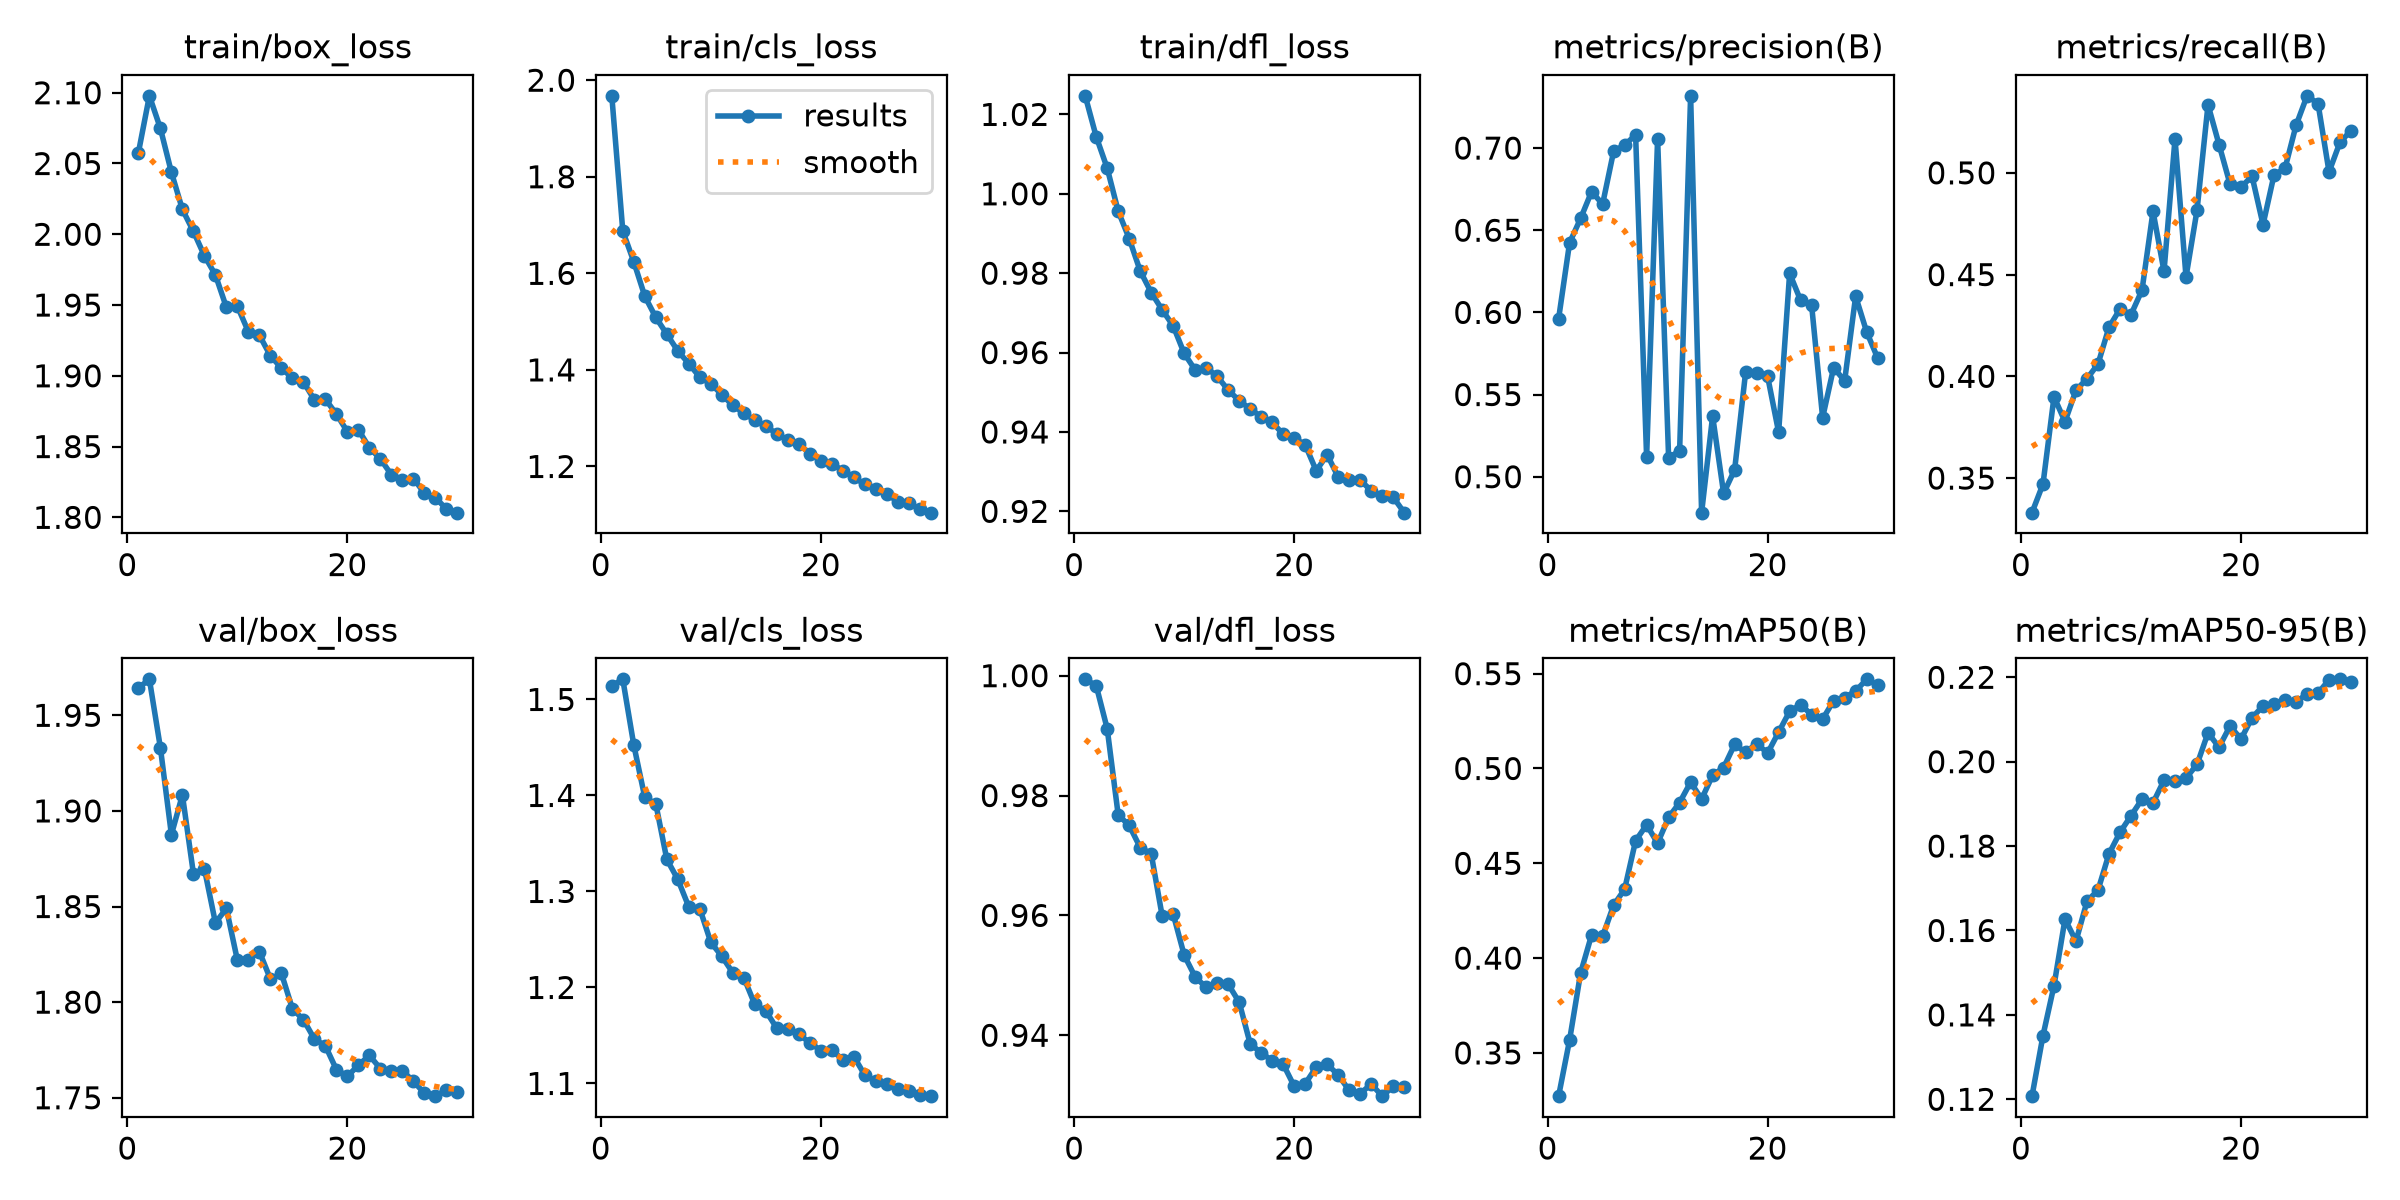

In [7]:
for filename, caption in [
    ('results.png', 'Historia treningu i walidacji. Górny rząd pokazuje straty treningowe oraz precision i recall, a dolny straty walidacyjne i mAP.'),
]:
    display(Markdown(f'**{caption}**'))
    display(Image(filename=str(RUN / filename), width=950))

### Krzywe detekcji na zbiorze testowym

Każdy kolor na wykresie odpowiada jednej klasie, a linia zbiorcza podsumowuje wszystkie klasy. Krzywe opisują detekcję z rozróżnieniem pięciu klas. Wcześniejsza tabela lokalizacji grupuje zaś wszystkie kolory sygnalizatorów w jedną kategorię.

**Precision–Recall. Pokazuje, jak zmienia się precyzja przy wykrywaniu coraz większego odsetka oznaczonych obiektów. Pole pod krzywą wiąże się z AP danej klasy.**

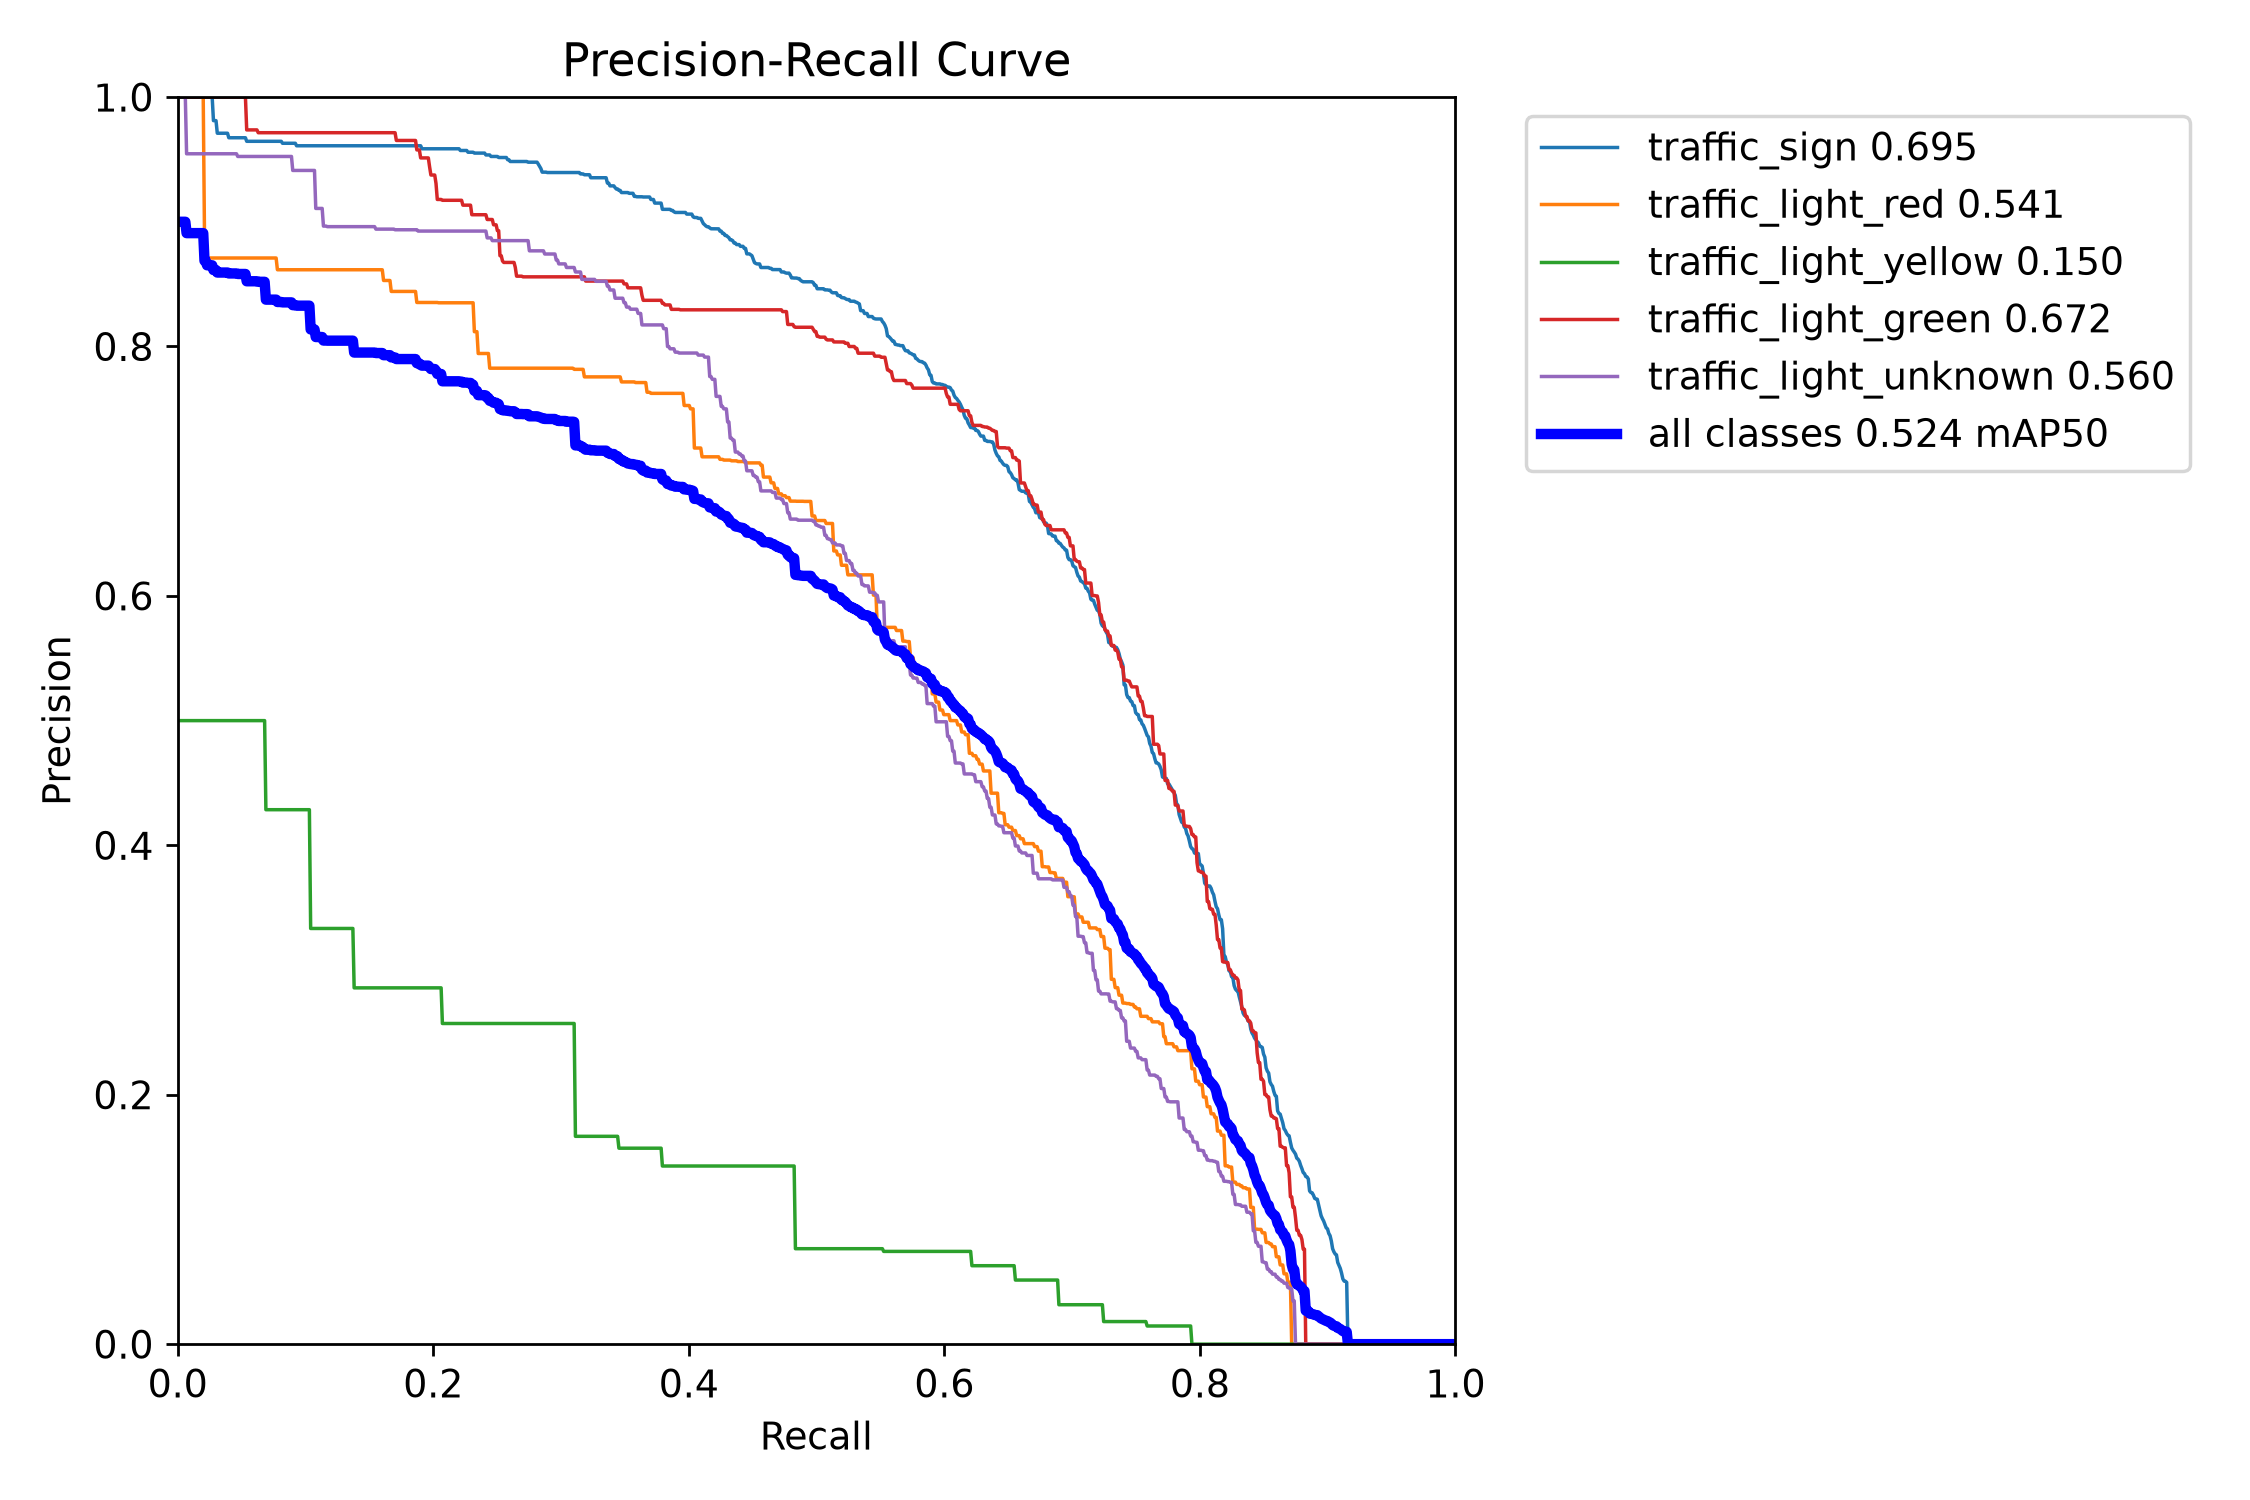

**F1 w zależności od progu pewności. Szczyt pokazuje najlepszy kompromis precision–recall na tym wykresie. Próg 0,25 w porównaniu z COCO ustalono wspólnie dla obu modeli.**

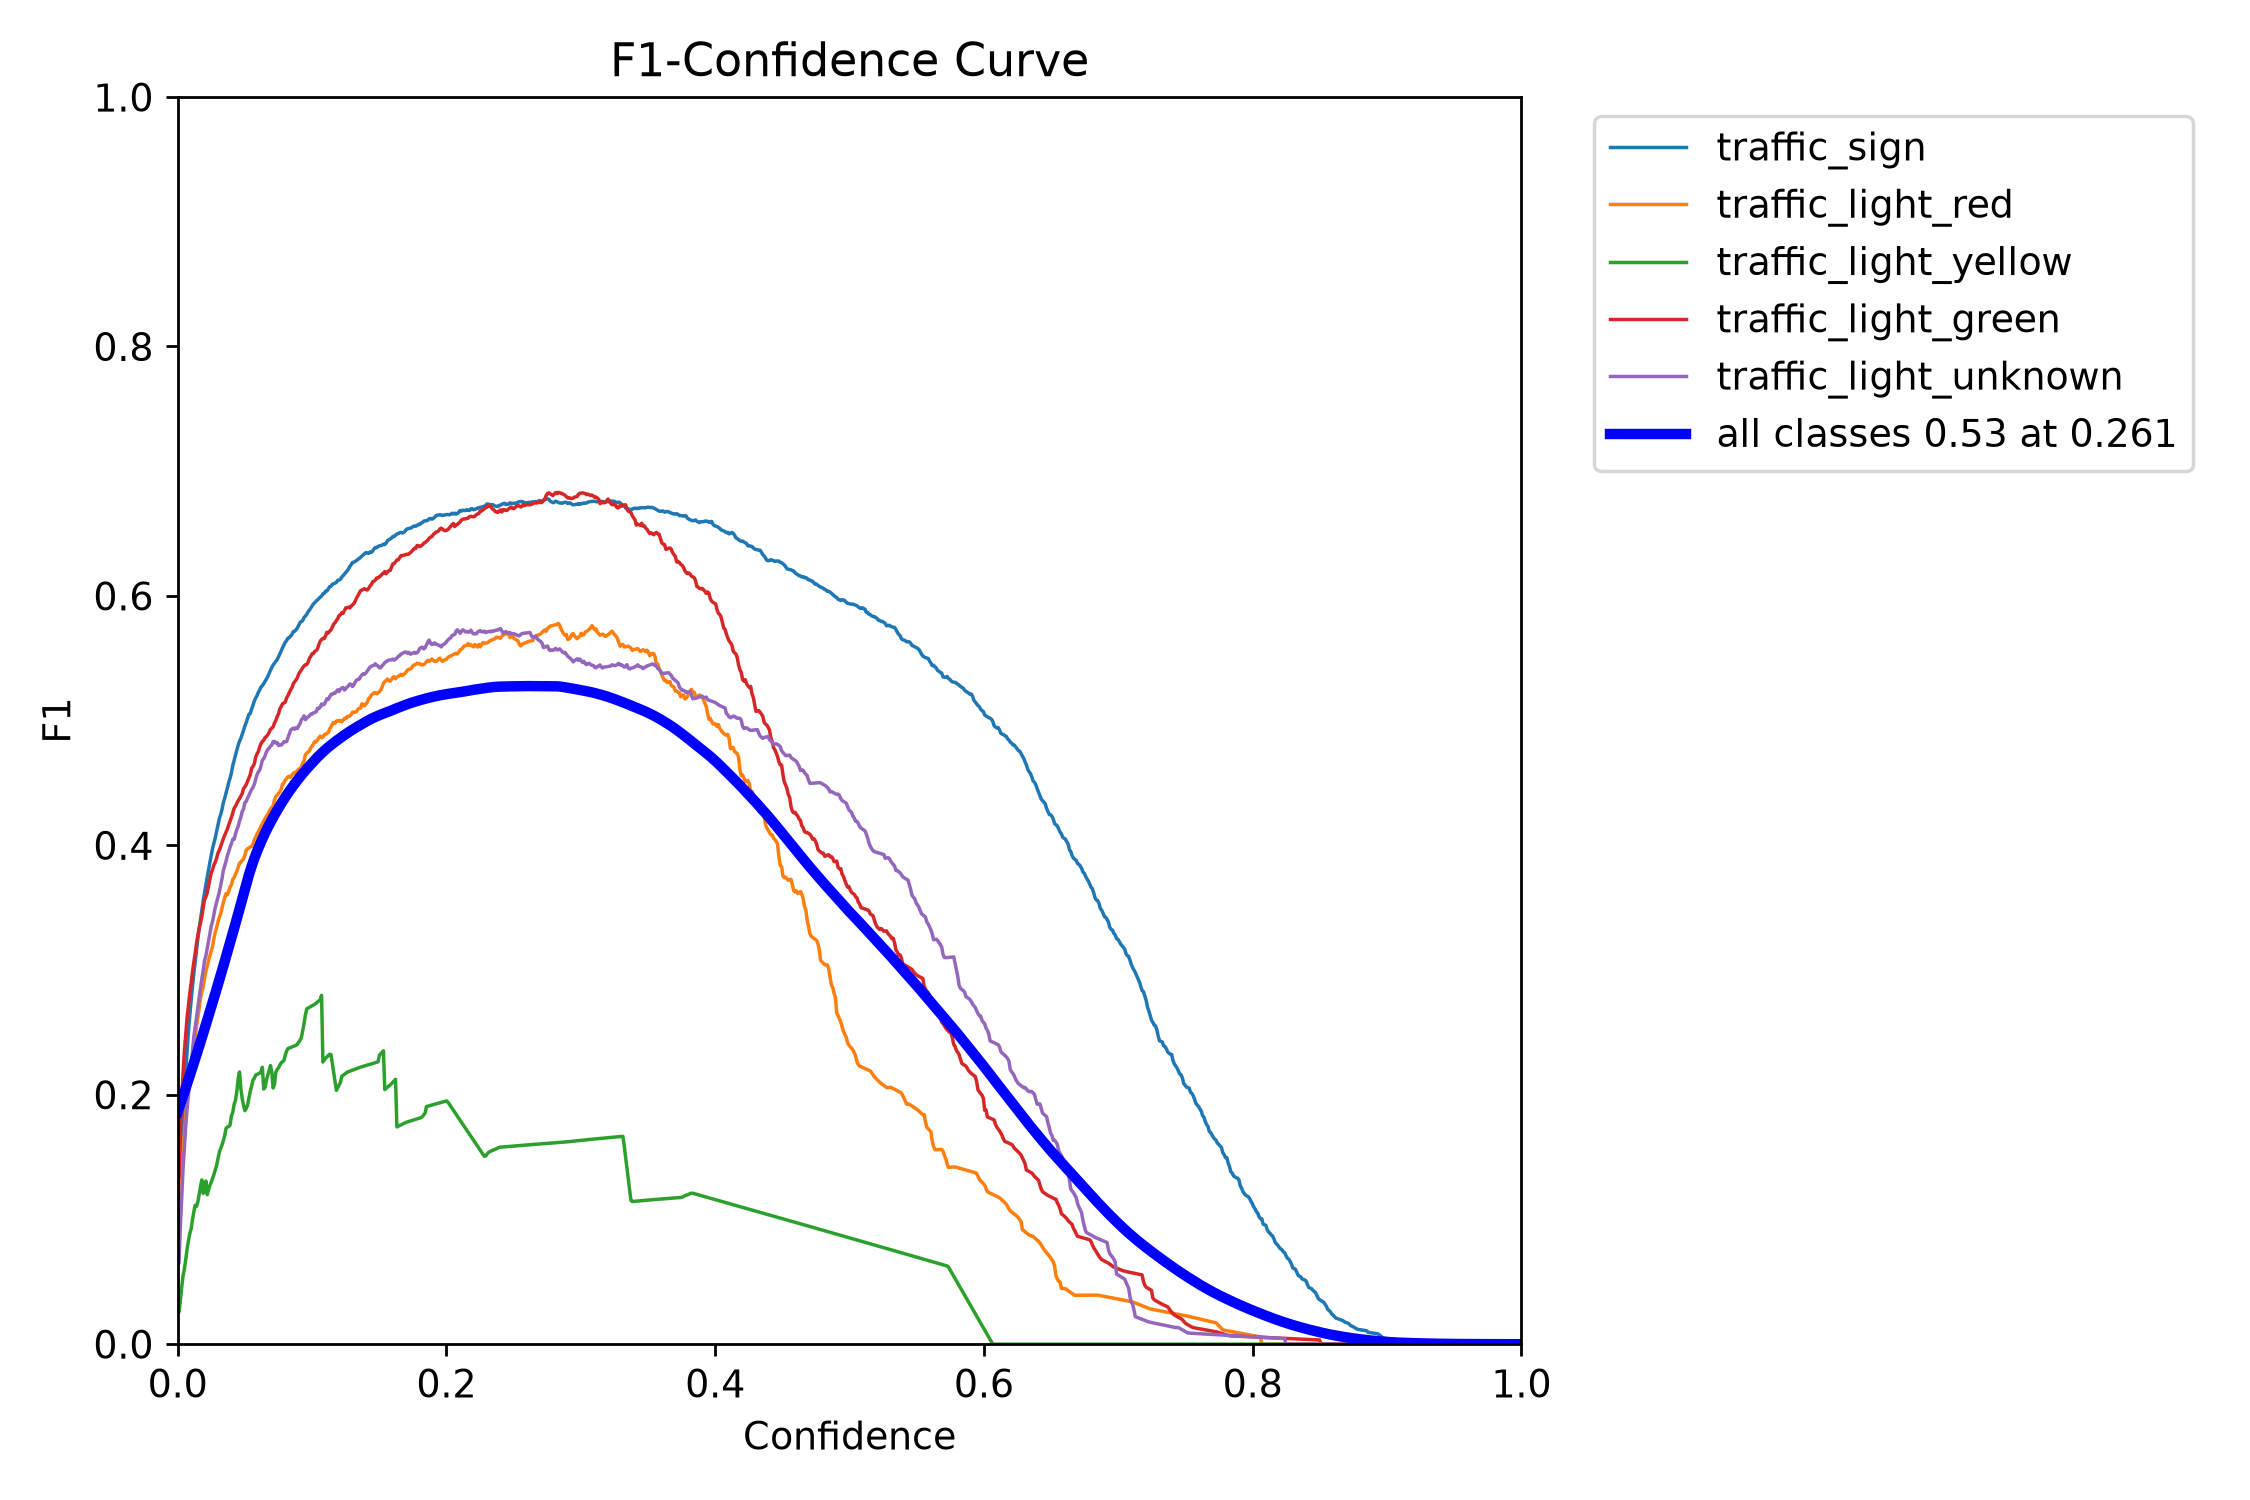

**Precision w zależności od progu pewności. Odpowiada na pytanie, jaki odsetek zwróconych detekcji jest poprawny.**

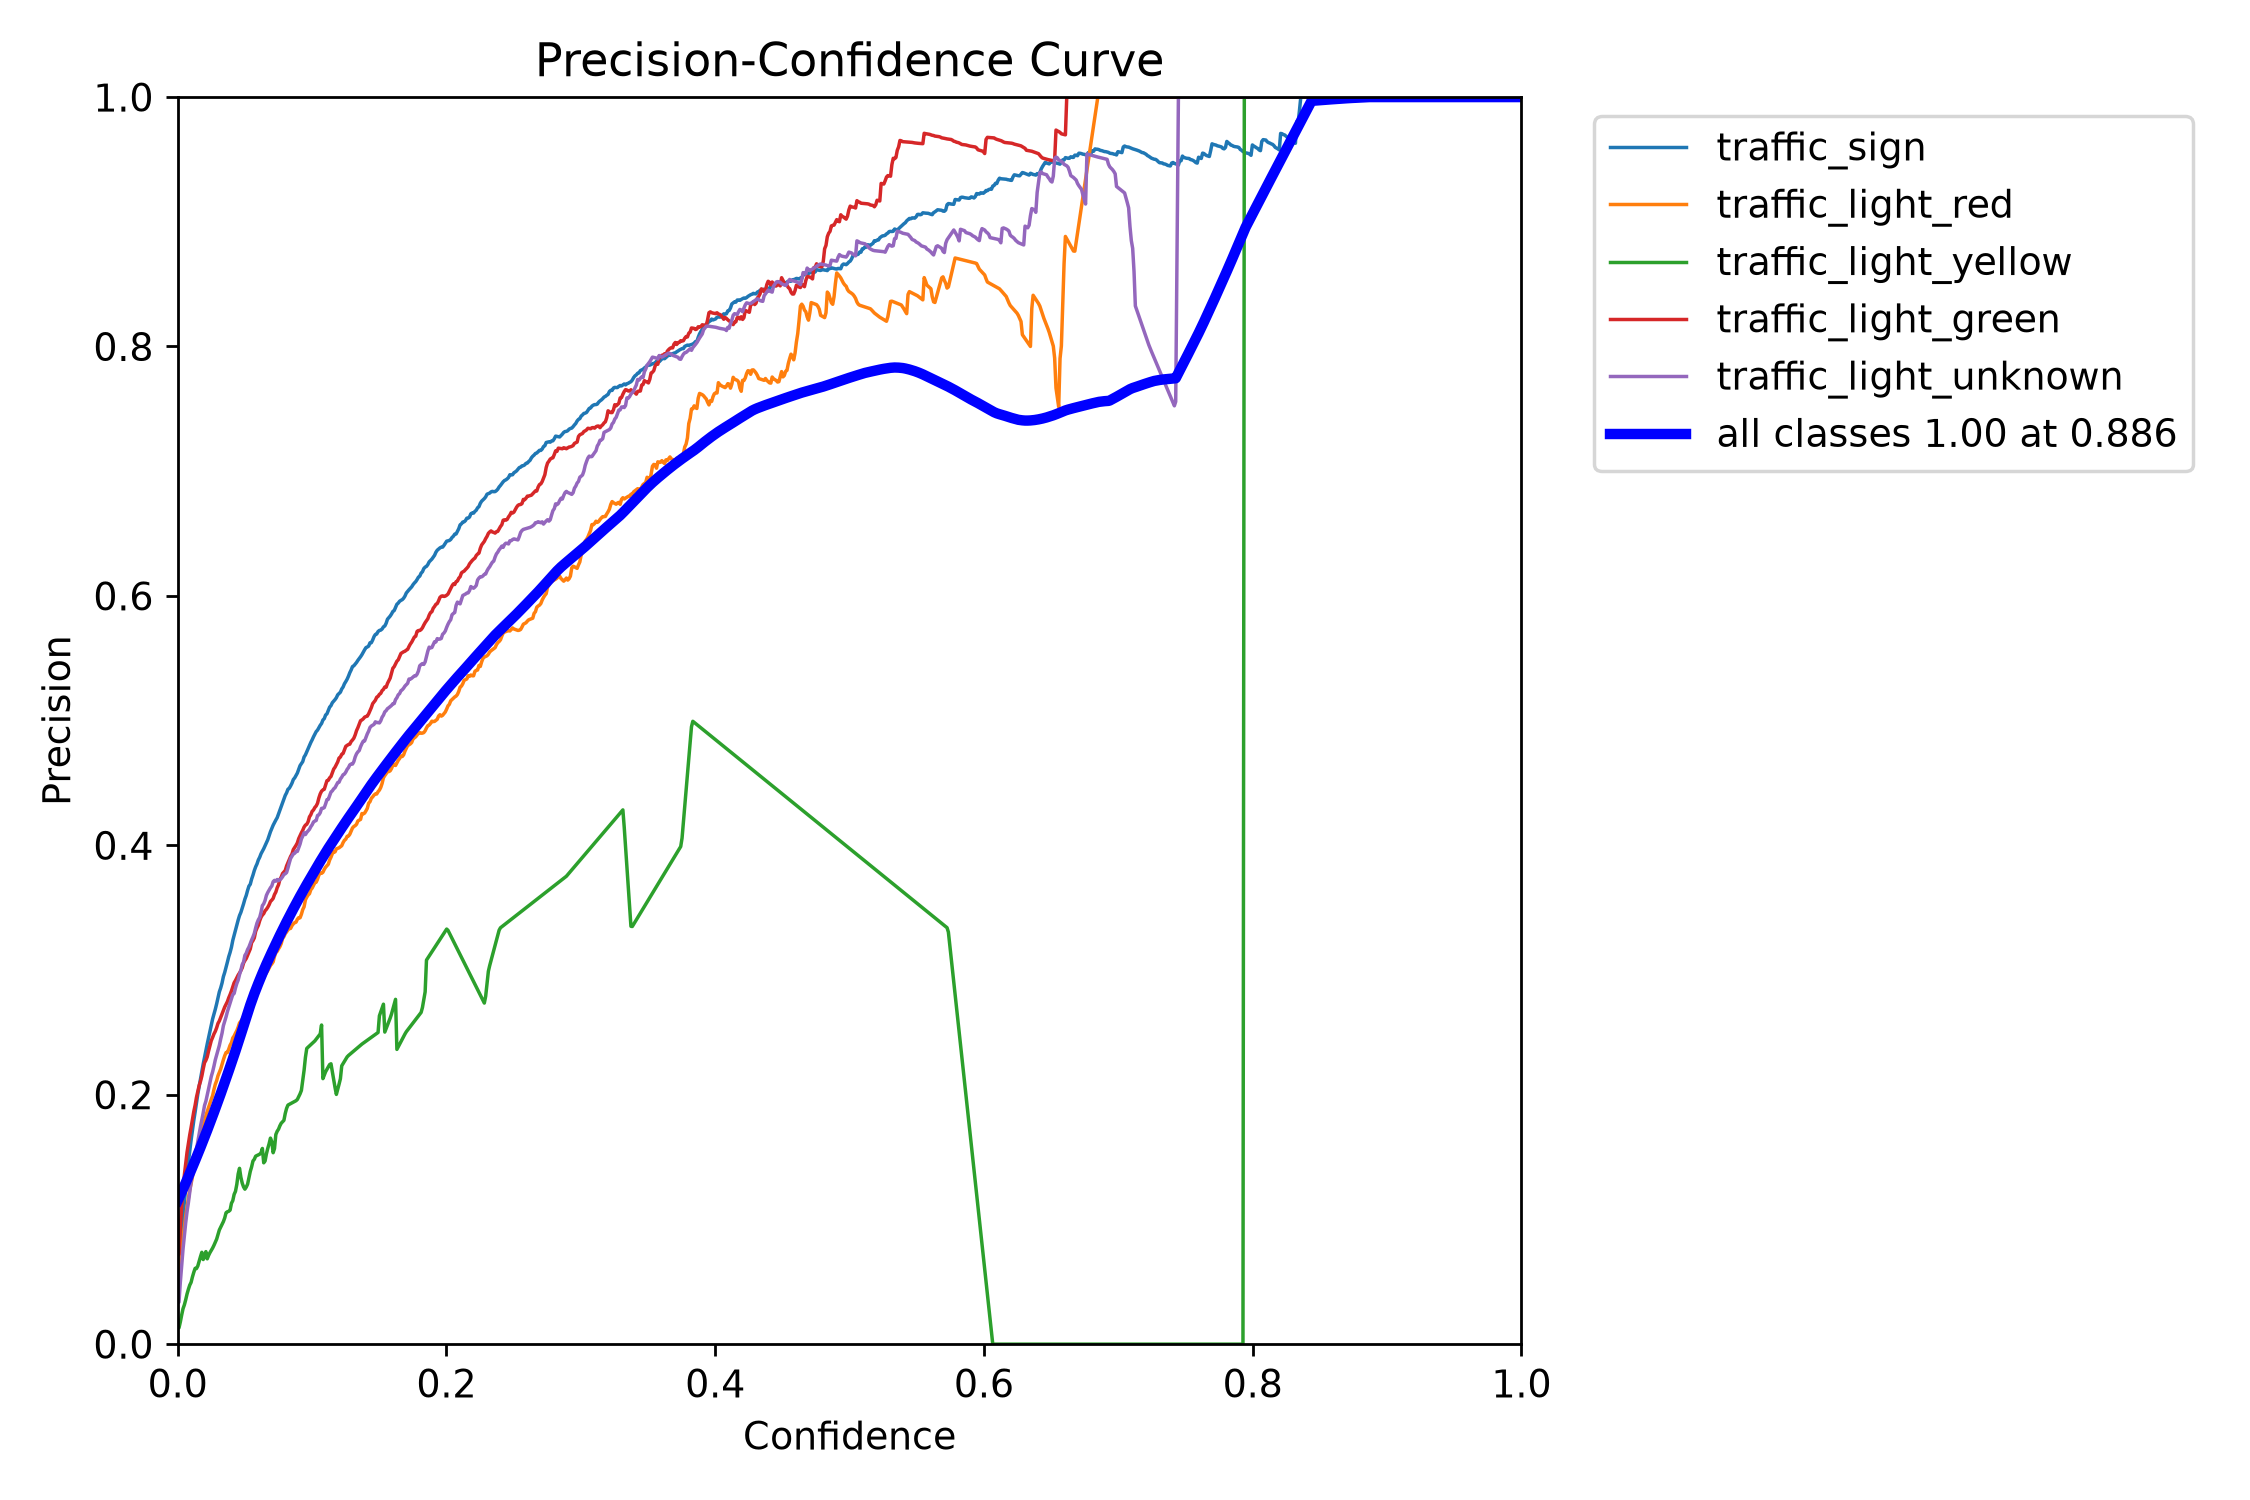

**Recall w zależności od progu pewności. Odpowiada na pytanie, jaki odsetek oznaczonych obiektów został wykryty.**

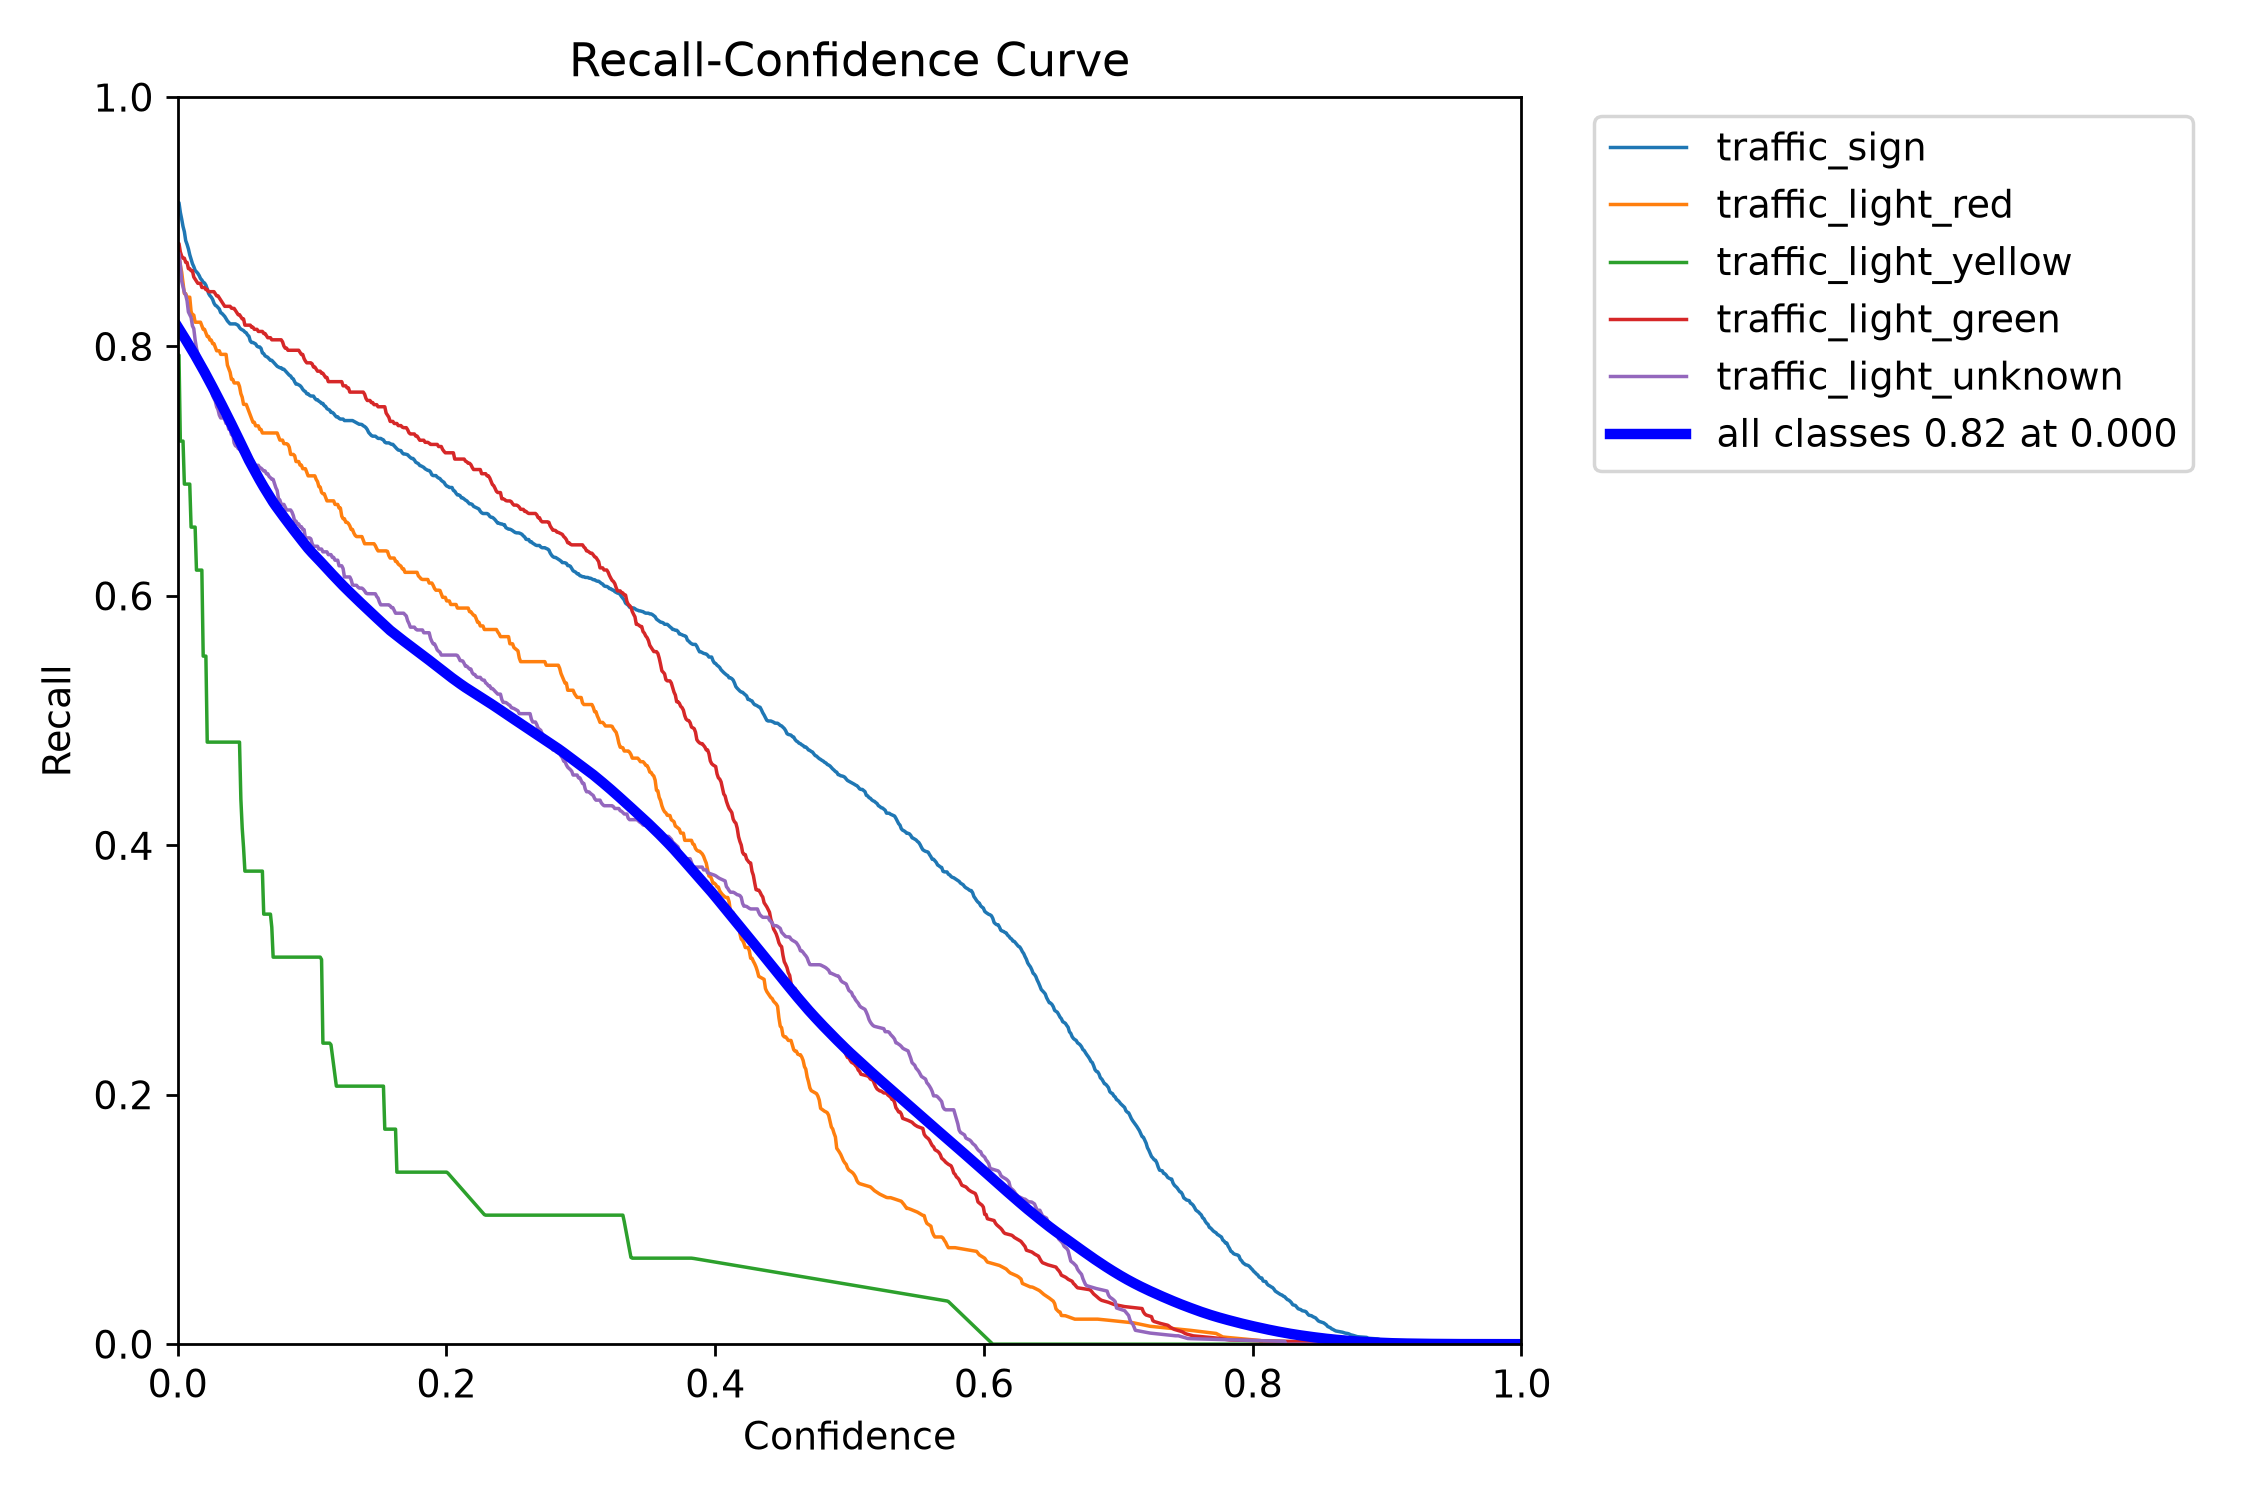

In [8]:
for filename, caption in [
    ('test/BoxPR_curve.png', 'Precision–Recall. Pokazuje, jak zmienia się precyzja przy wykrywaniu coraz większego odsetka oznaczonych obiektów. Pole pod krzywą wiąże się z AP danej klasy.'),
    ('test/BoxF1_curve.png', 'F1 w zależności od progu pewności. Szczyt pokazuje najlepszy kompromis precision–recall na tym wykresie. Próg 0,25 w porównaniu z COCO ustalono wspólnie dla obu modeli.'),
    ('test/BoxP_curve.png', 'Precision w zależności od progu pewności. Odpowiada na pytanie, jaki odsetek zwróconych detekcji jest poprawny.'),
    ('test/BoxR_curve.png', 'Recall w zależności od progu pewności. Odpowiada na pytanie, jaki odsetek oznaczonych obiektów został wykryty.'),
]:
    display(Markdown(f'**{caption}**'))
    display(Image(filename=str(RUN / filename), width=950))

### Znormalizowana macierz pomyłek Ultralytics na zbiorze testowym

Oś pozioma pokazuje klasę rzeczywistą, a pionowa klasę przewidzianą. Dla każdej rzeczywistej klasy wartości w kolumnie pokazują udziały. Przykładowo 0,20 w wierszu przewidywanego koloru czerwonego oznacza, że 20% obiektów z danej kolumny przypisano do klasy czerwonej. Przekątna pokazuje udziały trafień danej klasy. Wiersz `background` pokazuje pominięte adnotacje, a kolumna `background` rozkład fałszywych detekcji według przewidzianej klasy.

Normalizacja ułatwia porównanie klasy żółtej (29 adnotacji) z zieloną (596). Macierz pokazuje proporcje, więc liczebności pomyłek kolorów można odczytać we wcześniejszej tabeli. Tamta ocena dotyczy sygnalizatorów przy progu pewności 0,25 i IoU ≥ 0,50. Poniższa macierz obejmuje wszystkie pięć klas i stosuje procedurę ewaluacji Ultralytics.

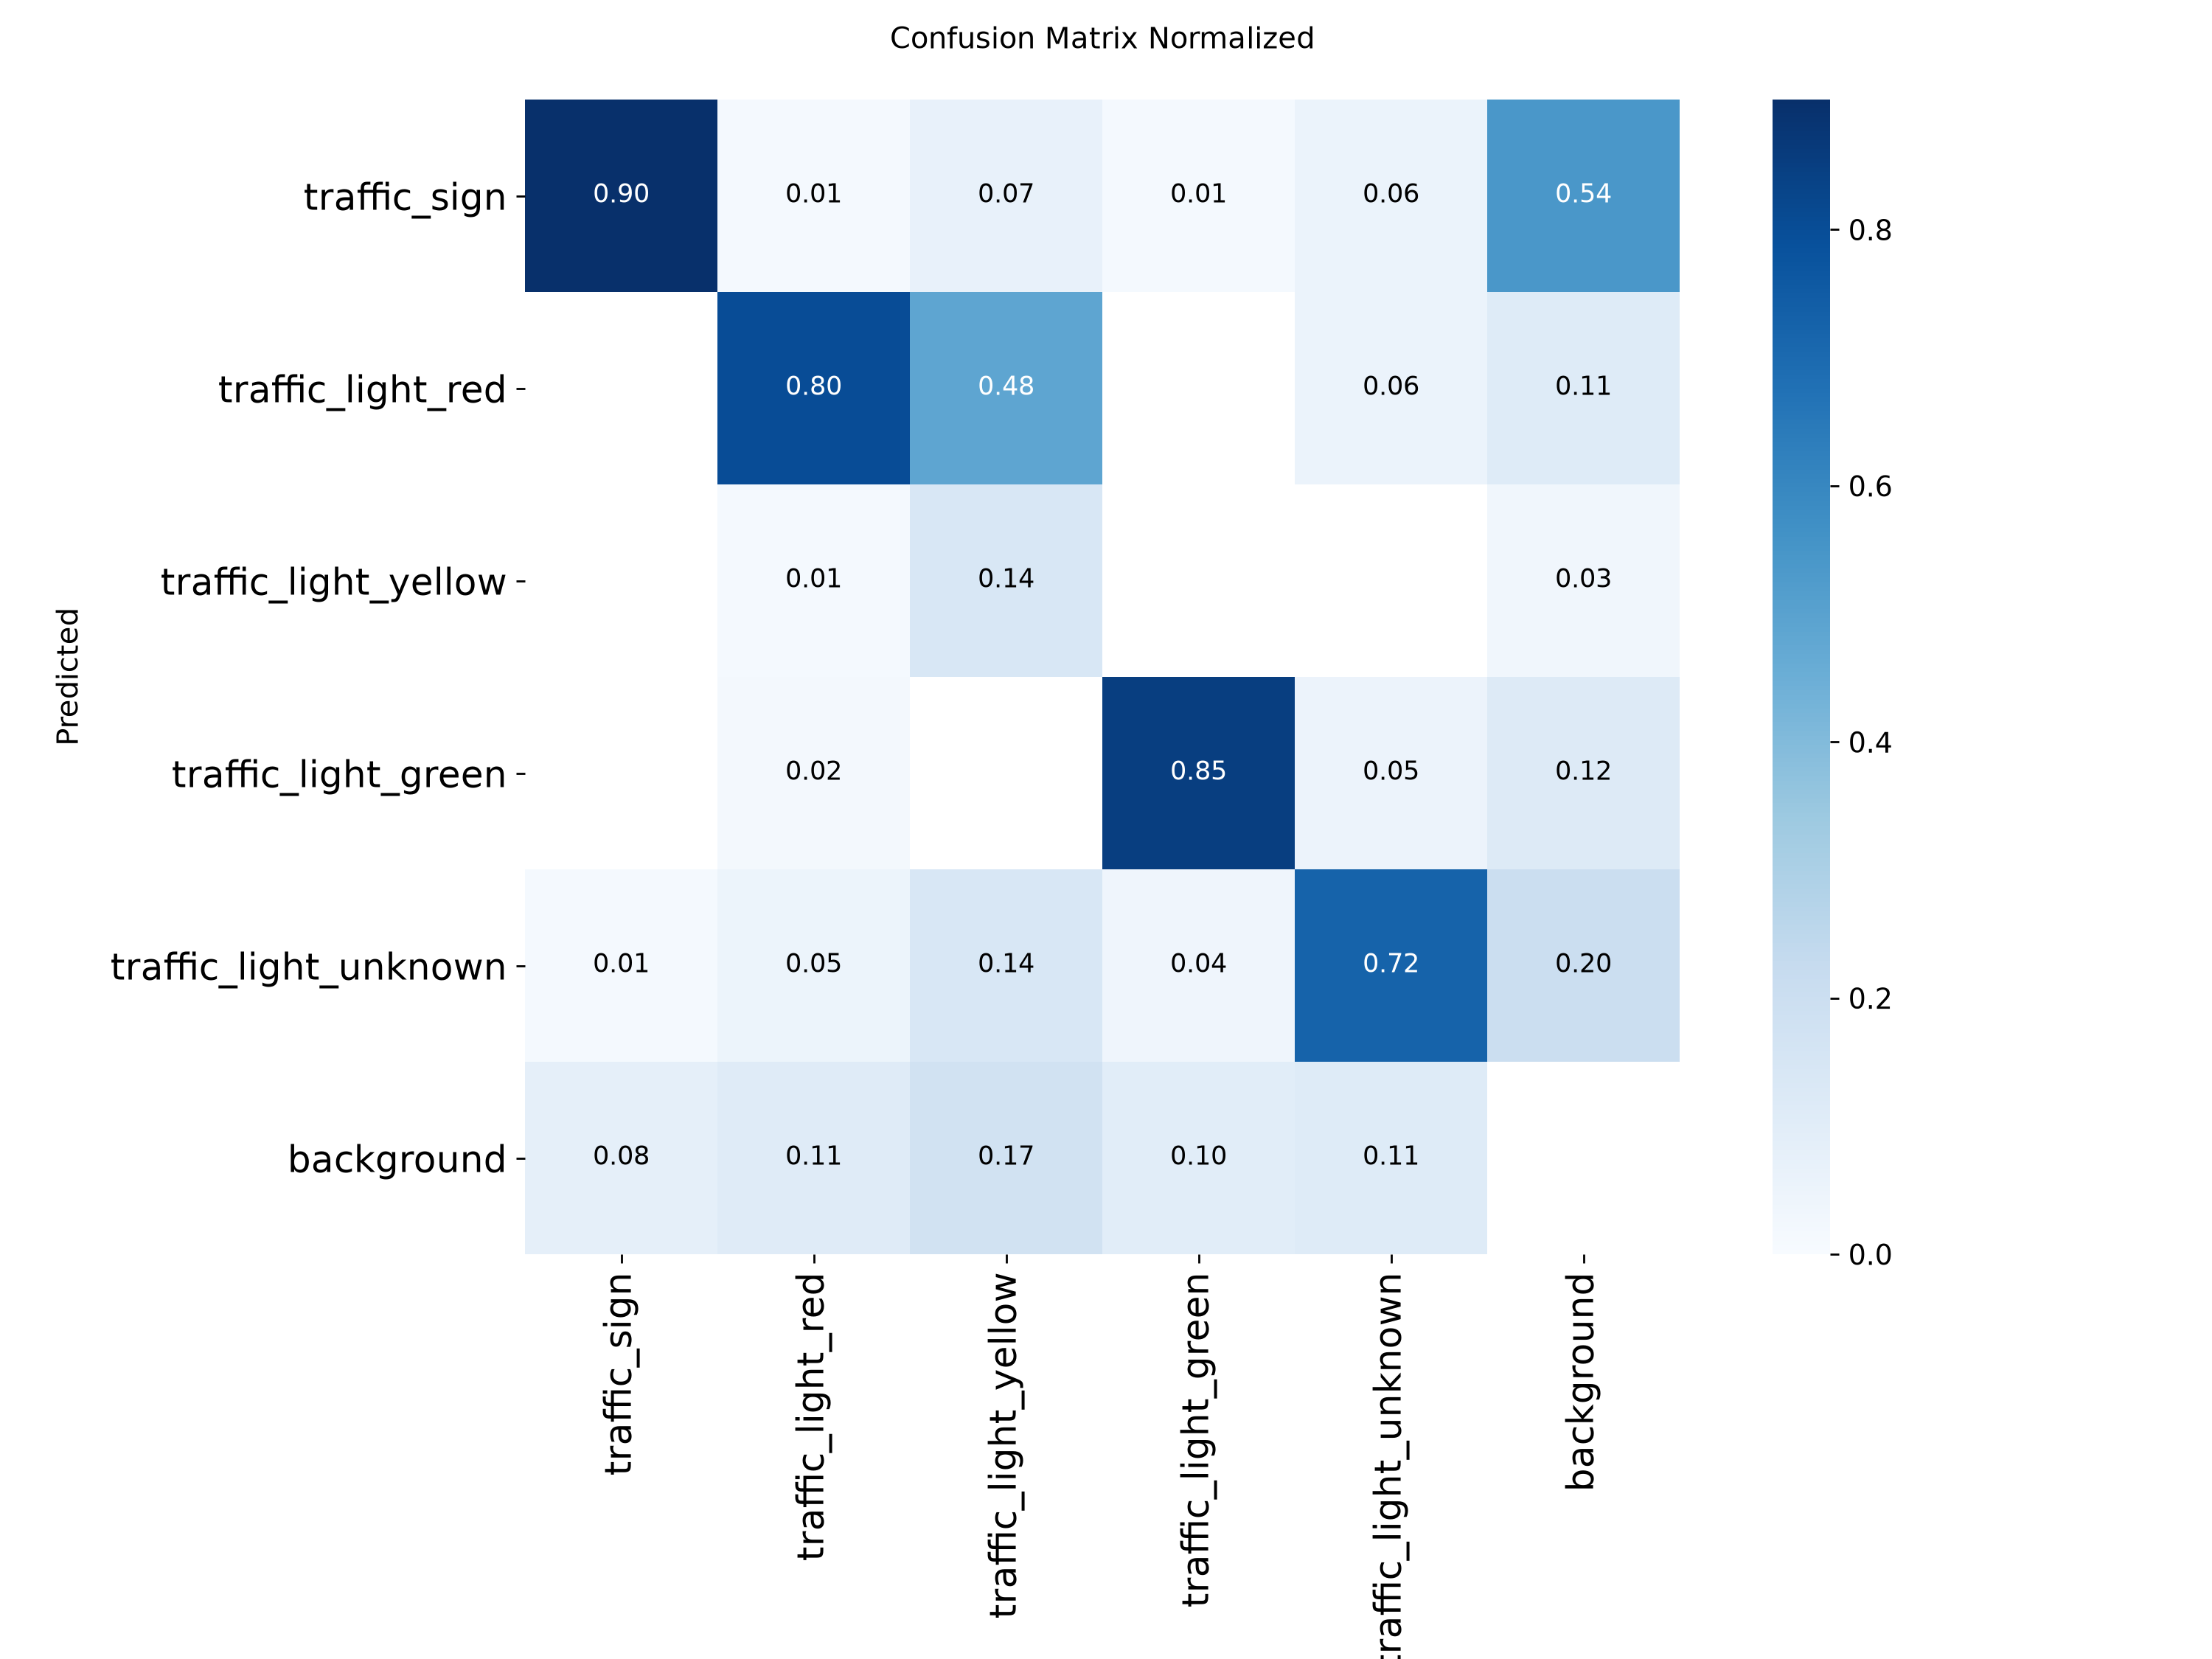

In [9]:
display(Image(filename=str(RUN / "test/confusion_matrix_normalized.png"), width=950))

## Wnioski

- **Sygnalizatory.** Przy tym samym progu pewności recall lokalizacji wzrósł z 16,5% do 60,7%. Model po fine-tuningu trafia w 627 dodatkowych sygnalizatorów. Liczba fałszywych alarmów wzrosła ze 162 do 331, a precision mimo to wzrosło, ponieważ liczba trafień rosła szybciej.
- **Znaki.** Wysokie precision modelu COCO opiera się na zaledwie 9 predykcjach klasy STOP. Po dostrojeniu model obejmuje całą klasę znaków drogowych BDD100K i trafia w 1083 z 1677 ramek.
- **Kolor.** W całym teście model pominął 559 sygnalizatorów i przypisał błędną klasę 59 spośród tych, które zlokalizował. Dla żółtego światła oba rodzaje błędów są widoczne, a jego wynik opiera się na 29 przykładach testowych.

## Porównanie z podejściem hybrydowym z Lab 2B

W wariancie hybrydowym YOLOv5su z wagami COCO lokalizuje sygnalizator, a osobny klasyfikator rozpoznaje kolor na wycinku z ramki YOLO. Model po fine-tuningu na BDD100K zwraca ramkę i klasę koloru z jednej sieci. Porównanie obejmuje te same 500 zdjęć testowych i 1421 oznaczonych sygnalizatorów. W obu przypadkach próg dopasowania ramki to IoU ≥ 0,50.

| Metryka | Hybryda z Lab 2B | YOLO po fine-tuningu |
|---|---:|---:|
| Rozdzielczość wejściowa / próg pewności | 1280 px / 0,10 | 960 px / 0,25 |
| Trafione ramki (TP) | 519 | 862 |
| Fałszywe alarmy (FP) | 745 | 331 |
| Pominięte sygnalizatory (FN) | 902 | 559 |
| Precision lokalizacji | 41,1% | 72,3% |
| Recall lokalizacji | 36,5% | 60,7% |
| **F1 lokalizacji** | **38,7%** | **66,0%** |
| Poprawna klasa koloru wśród trafionych ramek | 84,6% z 519 | 93,2% z 862 |
| **Poprawna ramka i klasa koloru wśród wszystkich sygnalizatorów** | **30,9% (439 / 1421)** | **56,5% (803 / 1421)** |

Po fine-tuningu F1 lokalizacji wzrosło o **27,3 p.p.** Model trafił w **343 dodatkowe ramki** i zgłosił **414 mniej fałszywych alarmów**. W ostatnim wierszu obie metody mają wspólny mianownik. Sygnalizator liczy się tam jako sukces tylko wtedy, gdy model poprawnie wyznaczył ramkę i przewidział klasę koloru. Liczbę 439 odtworzono z zapisanej dokładności 0,846 i 519 trafień.

Tabela zestawia gotowe warianty przy ich ustawieniach. Wiersz z dokładnością koloru na trafionych ramkach dotyczy osobnego podzbioru dla każdej metody. Wpływ samego fine-tuningu na lokalizację pokazuje wcześniejsze porównanie z COCO przy wspólnej rozdzielczości i progu.

Źródło wyników hybrydy — [Lab 2B, sekcja 4](lab2B_yolo.ipynb).